In [1]:
import os
import sys
import re

import string
import subprocess
import xarray as xr
import rasterio
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import netCDF4
from netCDF4 import MFDataset
from netCDF4 import Dataset
from IPython.display import display, Math, Latex
import pandas as pd
from matplotlib import cm
import datetime
from datetime import datetime, timedelta
from operator import * 
from matplotlib.dates import DateFormatter

import cartopy.crs as ccrs
import cartopy.feature as cfeature


## Load data

In [2]:
import xarray as xr
import numpy as np
import warnings

# Suppress runtime warnings for empty slices (common in masked ocean/land areas)
warnings.filterwarnings('ignore', category=RuntimeWarning)

# ==========================================
# 1. Load Forcing Datasets
# ==========================================
# Note: Dropped BA, DD, and YIELD as requested
path = '/Users/bilir/Desktop/CardamomScratch'

T2M_MIN = xr.open_dataset(f'{path}/ERA5_1deg_2000-2025/ERA5_T2MMIN_1x1_2000-2025.nc').sortby('latitude')
T2M_MAX = xr.open_dataset(f'{path}/ERA5_1deg_2000-2025/ERA5_T2MMAX_1x1_2000-2025.nc').sortby('latitude')
VPD = xr.open_dataset(f'{path}/ERA5_1deg_2000-2025/ERA5_VPD_1x1_2000-2025.nc').sortby('latitude')
TOTAL_PREC = xr.open_dataset(f'{path}/ObsDrivers05x05/IMERG/IMERGv07_interim_2000-2025_1x1.nc').sortby('latitude').drop_vars('empty', errors='ignore')
SNOW_IMERG = xr.open_dataset(f'{path}/ObsDrivers05x05/IMERG/IMERGv07_SNOWFALL_2000-2025_1x1.nc').sortby('latitude') 
CO2 = xr.open_dataset(f'{path}/ERA5_1deg_2000-2025/NOAAMLO_CO2_2000-2025.nc').sortby('latitude')
STRD = xr.open_dataset(f'{path}/ERA5_1deg_2000-2025/ERA5_STRD_1x1_2000-2025_gapfilled.nc').sortby('latitude')
SSRD = xr.open_dataset(f'{path}/ERA5_1deg_2000-2025/ERA5_SSRD_1x1_2000-2025_gapfilled.nc').sortby('latitude')
SKT = xr.open_dataset(f'{path}/ERA5_1deg_2000-2025/ERA5_SKT_1x1_2000-2025_gapfilled.nc').sortby('latitude')
WIND = xr.open_dataset(f'{path}/ERA5_1deg_2000-2025/ERA5_WIND_1x1_2000-2025.nc').sortby('latitude')
# ==========================================
# 2. Build the Master Dataset
# ==========================================
# Align all coordinates using T2M_MIN as the base template
ds = xr.Dataset(coords={'time': T2M_MIN.time, 'latitude': T2M_MIN.latitude, 'longitude': T2M_MIN.longitude})

# Assign variables and metadata (incorporating your required attributes)
ds['T2M_MIN'] = T2M_MIN['TMIN']
ds['T2M_MIN'].attrs.update({'source': 'ERA5', 'units': 'degrees Celsius'})

ds['T2M_MAX'] = T2M_MAX['TMAX']
ds['T2M_MAX'].attrs.update({'source': 'ERA5', 'units': 'degrees Celsius'})

ds['T2M_avg'] = 0.5*(T2M_MIN['TMIN'] + T2M_MAX['TMAX'])
ds['T2M_avg'].attrs.update({'source': 'ERA5', 'units': 'degrees Celsius'})

ds['T2M_DTR'] = T2M_MAX['TMAX']-T2M_MIN['TMIN']
ds['T2M_DTR'].attrs.update({'source': 'ERA5', 'units': 'degrees Celsius'})

ds['VPD'] = VPD['VPD']
ds['VPD'].attrs.update({'source': 'ERA5', 'units': 'hPa'})

ds['TOTAL_PREC'] = TOTAL_PREC['PREC']
ds['TOTAL_PREC'].attrs.update({'source': 'IMERGv07 interim total precip regridded 0.1x0.1 to 1x1.', 'units': 'mm day-1'})

ds['SNOWFALL'] = SNOW_IMERG['SNOW']
ds['SNOWFALL'].attrs.update({'source': 'Snowfall partitioning imposed from ERA5', 'units': 'mm day-1'})

ds['CO2'] = CO2['CO2']
ds['CO2'].attrs.update({'source': 'NOAA Mauna Loa CO2 record', 'units': 'ppm'})

ds['SKT'] = SKT['SKT_FILLED']
ds['SKT'].attrs.update({'source': 'ERA5', 'units': 'degrees Celsius'})

ds['SSRD'] = SSRD['SSRD_FILLED']
ds['SSRD'].attrs.update({'source': 'ERA5', 'units': 'MJ m-2 day-1'})

ds['STRD'] = STRD['STRD_FILLED']
ds['STRD'].attrs.update({'source': 'ERA5', 'units': 'MJ m-2 day-1'})

ds['WIND'] = WIND['WIND']
ds['WIND'].attrs.update({'source': 'ERA5', 'units': 'm s-1'})


climate_vars = ['T2M_MIN', 'T2M_MAX', 'VPD', 'TOTAL_PREC', 'SNOWFALL', 'SKT', 'SSRD', 'STRD', 'WIND']



# Detrending (optional side step)

In [3]:
# ==========================================
# 3. Vectorized Detrending: CO2 (Continuous)
# ==========================================
print("Detrending CO2 globally...")
# Fit degree-1 polynomial along time dimension for the whole globe
co2_fit = ds['CO2'].polyfit(dim='time', deg=1)
co2_trend = xr.polyval(ds['time'], co2_fit.polyfit_coefficients)

# Store global slope and detrended output
ds['CO2_trendslope'] = co2_fit.polyfit_coefficients.sel(degree=1)
ds['CO2_detrended'] = ds['CO2'] - (co2_trend - co2_trend.min(dim='time'))

# ==========================================
# 4. Vectorized Detrending: Climate (Monthly)
# ==========================================
print("Detrending Climate Variables monthly...")

for var in climate_vars:
    print(f"  Processing {var}...")
    detrended_months = []
    slopes_months = []
    
    # Isolate data by month and detrend directly
    for month in range(1, 13):
        # Filter for specific month
        da_m = ds[var].where(ds['time'].dt.month == month, drop=True)
        
        # Fit trend over the specific month across all years
        fit_m = da_m.polyfit(dim='time', deg=1)
        trend_m = xr.polyval(da_m['time'], fit_m.polyfit_coefficients)
        
        # Original math: data - (trend - trend.min)
        dt_m = da_m - (trend_m - trend_m.min(dim='time'))
        
        # Shift correction (adding original[0] - detrended[0])
        dt_corr_m = dt_m + (da_m.isel(time=0) - dt_m.isel(time=0))
        
        detrended_months.append(dt_corr_m)
        slopes_months.append(fit_m.polyfit_coefficients.sel(degree=1).assign_coords(month=month))

    # Recombine months and assign to the master dataset
    ds[f'{var}_detrended'] = xr.concat(detrended_months, dim='time').sortby('time')
    # Save slopes with an extra 'month' dimension (shape: month, latitude, longitude)
    ds[f'{var}_trendslope'] = xr.concat(slopes_months, dim='month')

# ==========================================
# 5. Non-Negative & SNOW/PREC Corrections
# ==========================================
print("Applying physical corrections...")

posdef_vars = ['SNOWFALL', 'SSRD', 'STRD', 'VPD', 'TOTAL_PREC','WIND']
for pv in posdef_vars:
    # Correct both raw and detrended versions
    ds[pv] = xr.where(ds[pv] < 1e-4, 0, ds[pv])
    ds[f'{pv}_detrended'] = xr.where(ds[f'{pv}_detrended'] < 1e-4, 0, ds[f'{pv}_detrended'])

# Snowfall vs Precipitation Correction on Detrended data
snow_exceeds = ds['SNOWFALL_detrended'] > ds['TOTAL_PREC_detrended']
avg_prec_snow = (ds['SNOWFALL_detrended'] + ds['TOTAL_PREC_detrended']) / 2.0

ds['SNOWFALL_detrended'] = xr.where(snow_exceeds, avg_prec_snow, ds['SNOWFALL_detrended'])
ds['TOTAL_PREC_detrended'] = xr.where(snow_exceeds, avg_prec_snow, ds['TOTAL_PREC_detrended'])

# Optional: Apply same correction to raw variables if desired
snow_exceeds_raw = ds['SNOWFALL'] > ds['TOTAL_PREC']
avg_prec_snow_raw = (ds['SNOWFALL'] + ds['TOTAL_PREC']) / 2.0
ds['SNOWFALL'] = xr.where(snow_exceeds_raw, avg_prec_snow_raw, ds['SNOWFALL'])
ds['TOTAL_PREC'] = xr.where(snow_exceeds_raw, avg_prec_snow_raw, ds['TOTAL_PREC'])

# ==========================================
# 6. Formatting & Export
# ==========================================
print("Setting encodings and saving to NetCDF...")

# Ensure float64 and set NA values properly across all outputs
encoding_dict = {
    'time': {'dtype': 'float64', 'units': 'days since 2000-01-01', '_FillValue': None}
}

for var in ds.data_vars:
    ds[var] = ds[var].astype('float64')
    if 'time' in ds[var].dims: # Only apply fill values to data variables, not coordinate variables
        encoding_dict[var] = {'_FillValue': -9999.0}

# Save consolidated master file
output_file = f'{path}/ERA5_1deg_2000-2025/Global_Forcing_Detrended_Master_1x1.nc'
ds.to_netcdf(output_file, encoding=encoding_dict)
print(f"Successfully saved consolidated dataset to {output_file}!")

Detrending CO2 globally...
Detrending Climate Variables monthly...
  Processing T2M_MIN...
  Processing T2M_MAX...
  Processing VPD...
  Processing TOTAL_PREC...
  Processing SNOWFALL...
  Processing SKT...
  Processing SSRD...
  Processing STRD...
  Processing WIND...
Applying physical corrections...
Setting encodings and saving to NetCDF...
Successfully saved consolidated dataset to /Users/bilir/Desktop/CardamomScratch/ERA5_1deg_2000-2025/Global_Forcing_Detrended_Master_1x1.nc!


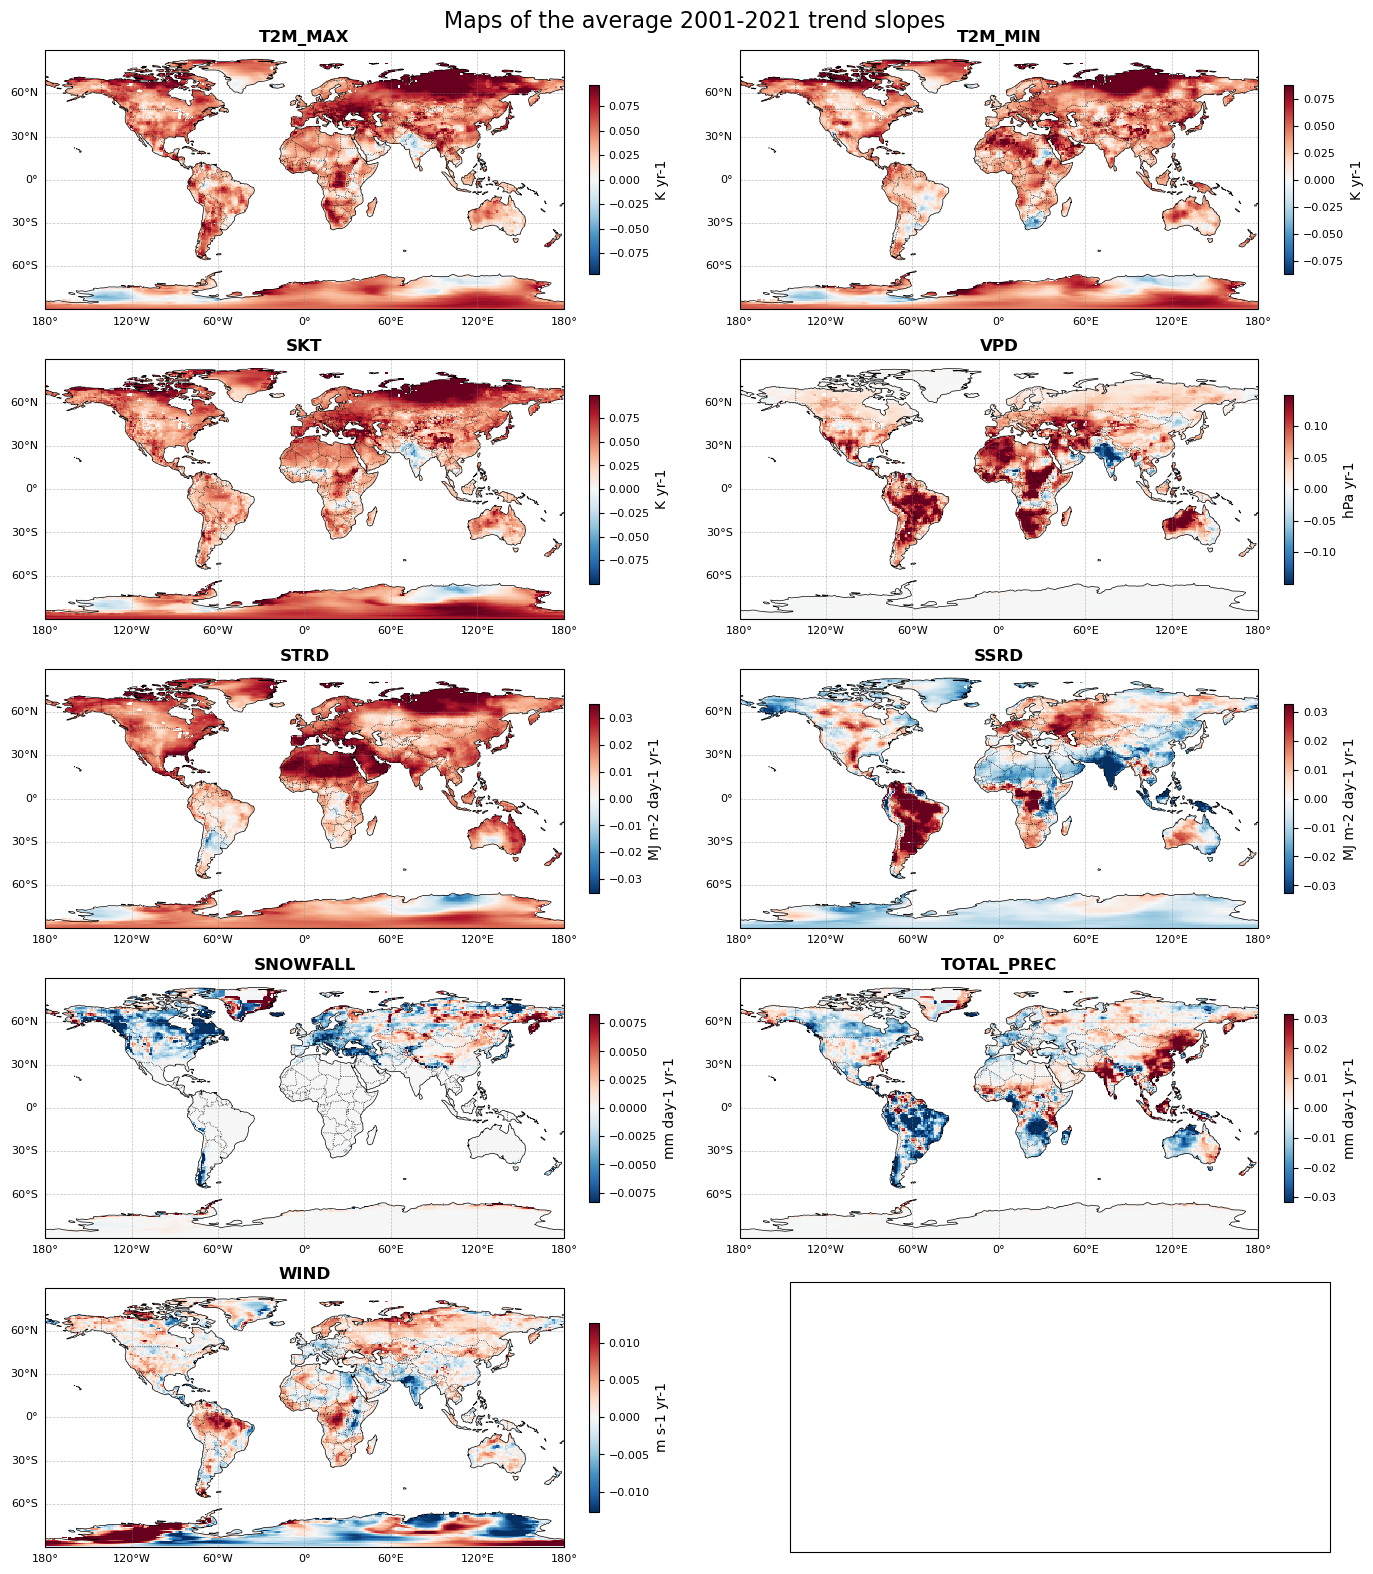

In [4]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# 1. Define the variables and their corresponding units based on your figure
variables = ['T2M_MAX', 'T2M_MIN', 'SKT', 'VPD', 'STRD', 'SSRD', 'SNOWFALL', 'TOTAL_PREC','WIND']
units = [
    'K yr-1', 'K yr-1', 'K yr-1', 'hPa yr-1', 
    'MJ m-2 day-1 yr-1', 'MJ m-2 day-1 yr-1', 
    'mm day-1 yr-1', 'mm day-1 yr-1','m s-1 yr-1'
]

# 2. Set up the figure and subplots with a PlateCarree projection
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(14, 16), 
                         subplot_kw={'projection': ccrs.PlateCarree()})
axes = axes.flatten()

# Note: xarray's polyfit over a datetime64 coordinate calculates the slope per nanosecond.
# To convert nanoseconds to years (assuming Julian years for simplicity):
ns_to_year = 1e9 * 60 * 60 * 24 * 365.25

for i, var in enumerate(variables):
    ax = axes[i]
    
    # Extract the trend slope variable and average across the months
    slope_var = f'{var}_trendslope'
    
    # Calculate the annual average slope and convert units from per-nanosecond to per-year
    # (If your time array is already integer days, change this multiplier to 365.25)
    data_to_plot = ds[slope_var].mean(dim='month') * ns_to_year
    
    # Determine symmetric colorbar limits (ignoring NaNs) to ensure white is exactly zero
    vmax = np.nanpercentile(np.abs(data_to_plot.values), 95) 
    vmin = -vmax
    
    # Plot the data
    im = data_to_plot.plot(
        ax=ax, 
        transform=ccrs.PlateCarree(),
        cmap='RdBu_r',       # Red-Blue diverging colormap (reversed)
        add_colorbar=False,  # We will add a custom colorbar manually
        vmin=vmin, 
        vmax=vmax
    )
    
    # Add map features
    ax.coastlines(linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
    ax.set_title(var, fontweight='bold', fontsize=12)
    
    # Add Gridlines and Labels
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}
    
    # Add Colorbar specific to this subplot
    cbar = fig.colorbar(im, ax=ax, orientation='vertical', shrink=0.7, pad=0.04)
    cbar.set_label(units[i], fontsize=10)
    cbar.ax.tick_params(labelsize=8)

# 3. Format and show
plt.suptitle('Maps of the average 2001-2021 trend slopes', fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

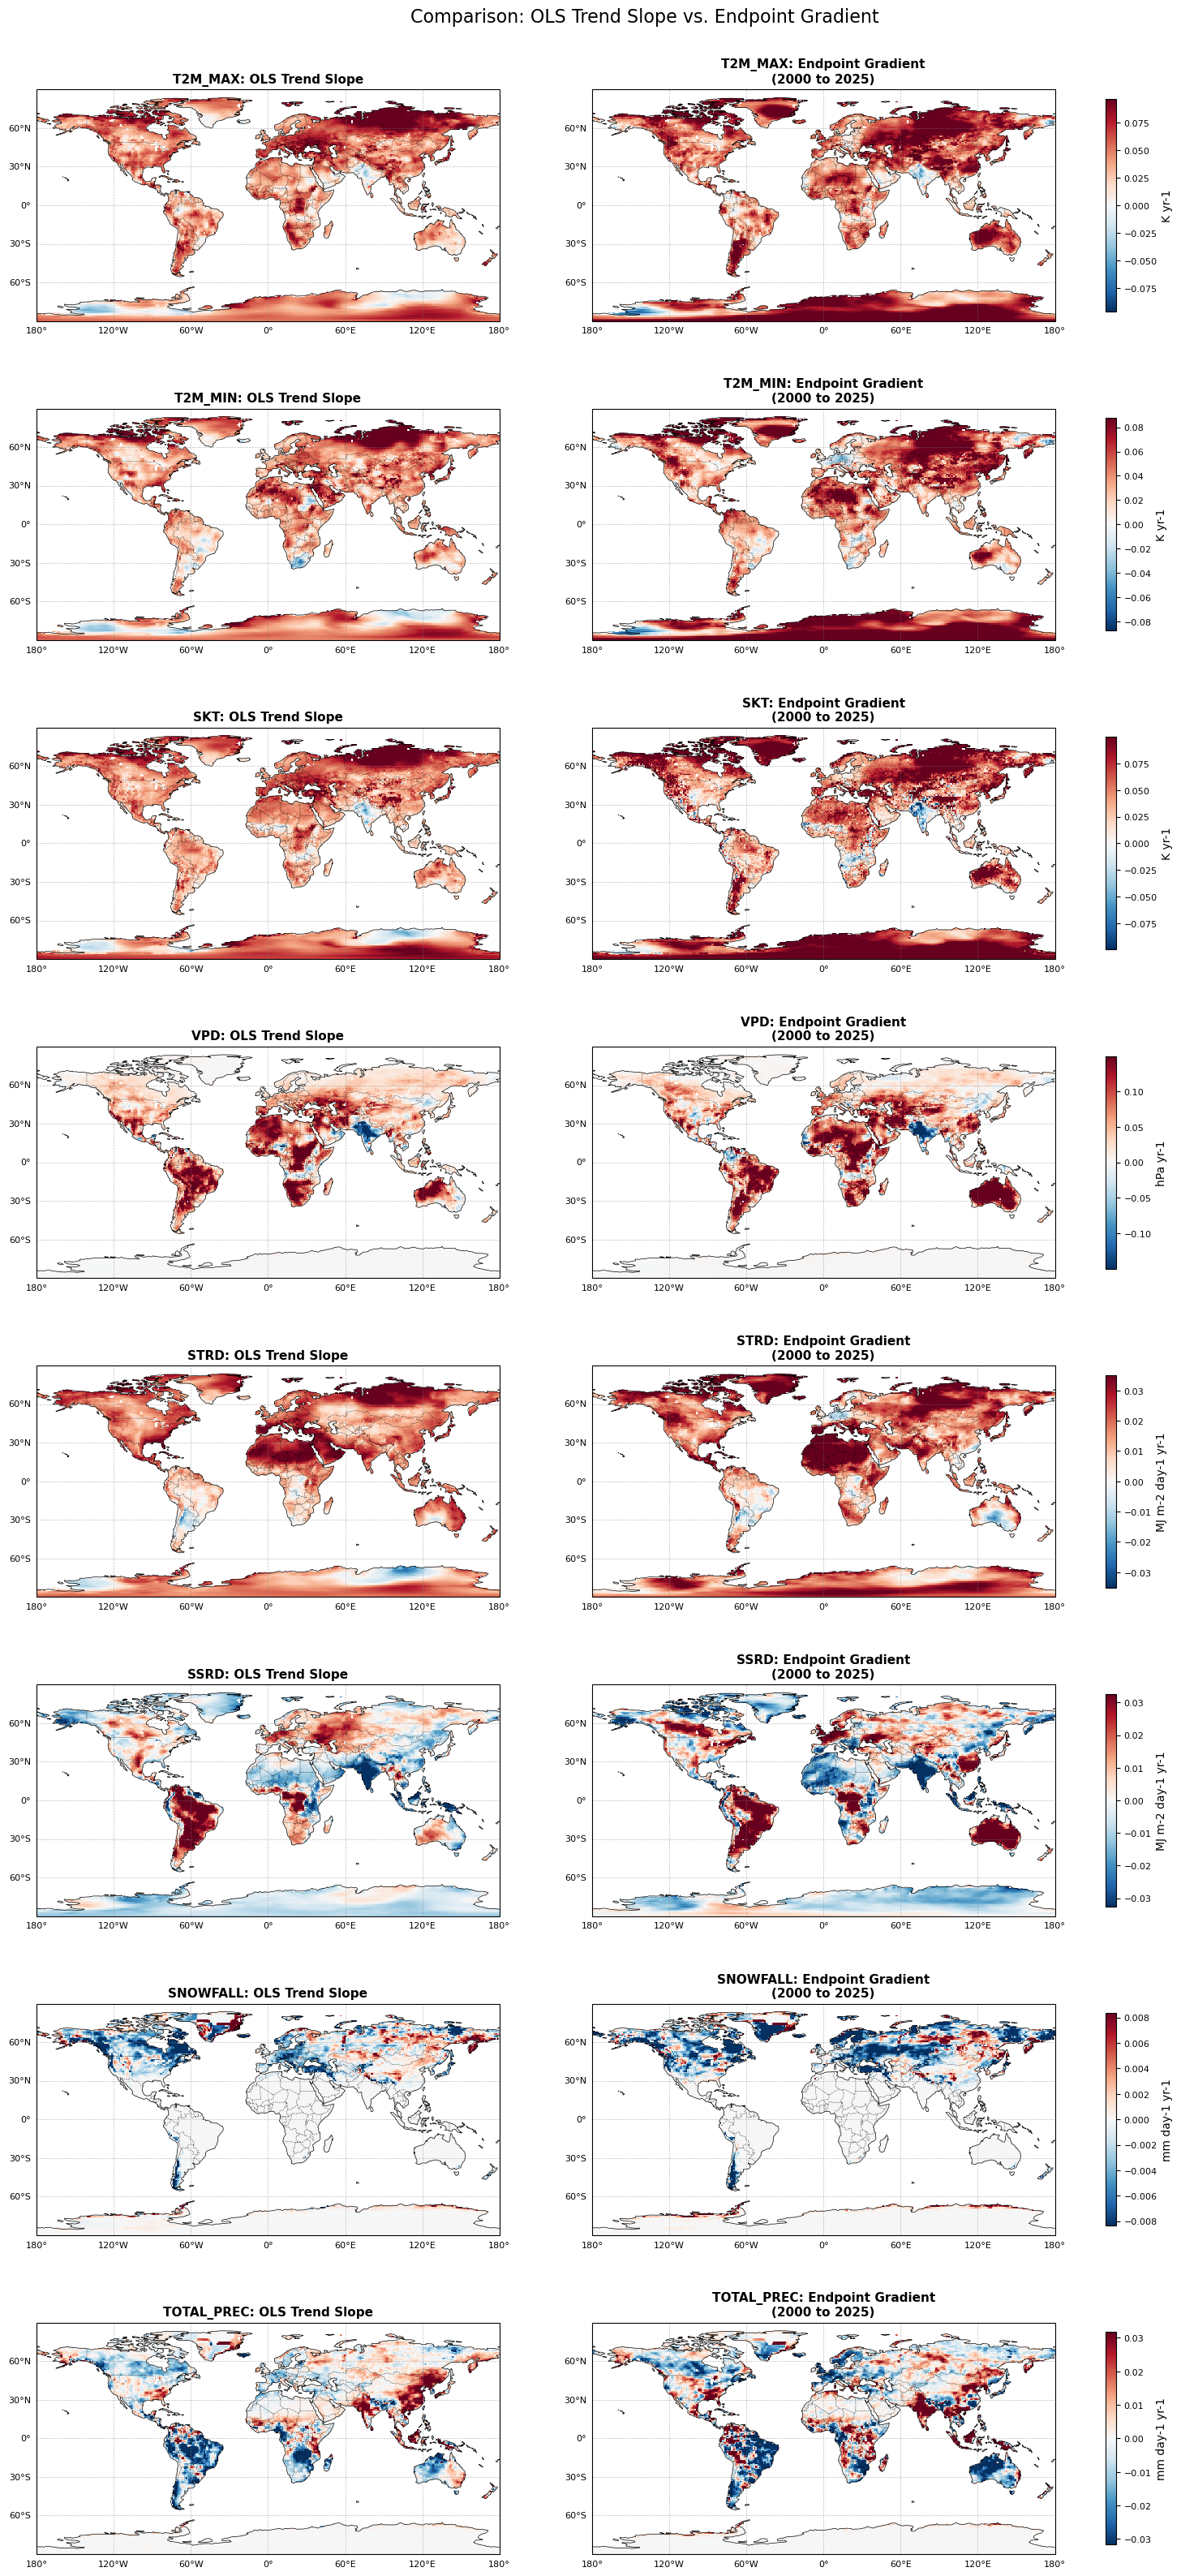

In [5]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# 1. Define variables and units (subset shown for clarity, you can add the rest)
variables = ['T2M_MAX', 'T2M_MIN', 'SKT', 'VPD', 'STRD', 'SSRD', 'SNOWFALL', 'TOTAL_PREC']
units = [
    'K yr-1', 'K yr-1', 'K yr-1', 'hPa yr-1', 
    'MJ m-2 day-1 yr-1', 'MJ m-2 day-1 yr-1', 
    'mm day-1 yr-1', 'mm day-1 yr-1'
]
# Conversion factor for OLS slopes (assuming datetime64 ns -> years)
ns_to_year = 1e9 * 60 * 60 * 24 * 365.25

# Identify start and end years for the gradient calculation
start_year = int(ds['time'].dt.year.min().item())
end_year = int(ds['time'].dt.year.max().item())
dt_years = end_year - start_year

# 2. Set up the figure (N rows x 2 columns)
fig, axes = plt.subplots(nrows=len(variables), ncols=2, figsize=(20, 5 * len(variables)), 
                         subplot_kw={'projection': ccrs.PlateCarree()})

for i, var in enumerate(variables):
    
    # --- CALCULATIONS ---
    
    # A) OLS Trend Slope (Annual Average)
    ols_slope = ds[f'{var}_trendslope'].mean(dim='month') * ns_to_year
    
    # B) Endpoint Gradient 
    val_start = ds[var].sel(time=ds['time'].dt.year == start_year).mean(dim='time')
    val_end = ds[var].sel(time=ds['time'].dt.year == end_year).mean(dim='time')
    endpoint_gradient = (val_end - val_start) / dt_years
    
    # Determine symmetric colorbar limits based on the OLS slope to keep the scale identical
    vmax = np.nanpercentile(np.abs(ols_slope.values), 95)
    vmin = -vmax
    
    # --- PLOTTING ---
    
    # Left Column: OLS Trend Slope
    ax_left = axes[i, 0]
    im_left = ols_slope.plot(
        ax=ax_left, transform=ccrs.PlateCarree(), cmap='RdBu_r', 
        add_colorbar=False, vmin=vmin, vmax=vmax
    )
    ax_left.set_title(f'{var}: OLS Trend Slope', fontweight='bold', fontsize=11)
    
    # Right Column: Endpoint Gradient
    ax_right = axes[i, 1]
    im_right = endpoint_gradient.plot(
        ax=ax_right, transform=ccrs.PlateCarree(), cmap='RdBu_r', 
        add_colorbar=False, vmin=vmin, vmax=vmax
    )
    ax_right.set_title(f'{var}: Endpoint Gradient\n({start_year} to {end_year})', fontweight='bold', fontsize=11)
    
    # --- MAP FORMATTING ---
    for ax in [ax_left, ax_right]:
        ax.coastlines(linewidth=0.5)
        ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
        gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {'size': 8}
        gl.ylabel_style = {'size': 8}
        
    # Add a single shared colorbar for the row
    cbar = fig.colorbar(im_right, ax=[ax_left, ax_right], orientation='vertical', shrink=0.8, pad=0.04)
    cbar.set_label(units[i], fontsize=10)
    cbar.ax.tick_params(labelsize=8)

plt.suptitle('Comparison: OLS Trend Slope vs. Endpoint Gradient', fontsize=16, y=0.9)
plt.show()

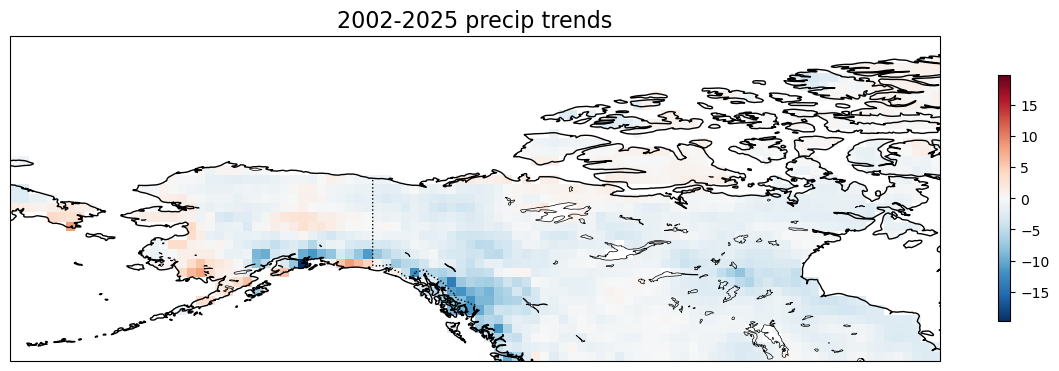

In [26]:


ols_slope = ds['SNOWFALL_trendslope'].mean(dim='month') * ns_to_year * 365.25

# Using .isel grabs by index. If you wanted degrees, use .sel(latitude=slice(...))
ols_slope_lim = ols_slope.isel(latitude=slice(140, 175), longitude=slice(0, 100))

# =====================================================================
# PLOT 2: Glacier-Free GRACE at 1 degree 
# =====================================================================

# Setup Cartopy Figure and Axis
plt.figure(figsize=(15, 8))
ax2 = plt.axes(projection=ccrs.PlateCarree())

# Add geographic context
ax2.coastlines(resolution='50m', color='black', linewidth=1)
ax2.add_feature(cfeature.BORDERS, linestyle=':', linewidth=1)
ax2.add_feature(cfeature.LAKES, facecolor='none', edgecolor='black', linewidth=0.5)

# Plotting - FIXED: Changed ax=ax_left to ax=ax2
C2 = ols_slope_lim.plot(
    ax=ax2, 
    transform=ccrs.PlateCarree(), 
    cmap='RdBu_r',add_colorbar=False, 
)
plt.colorbar(C2,shrink=.4)
plt.title('2002-2025 precip trends', fontsize=16)
plt.show()

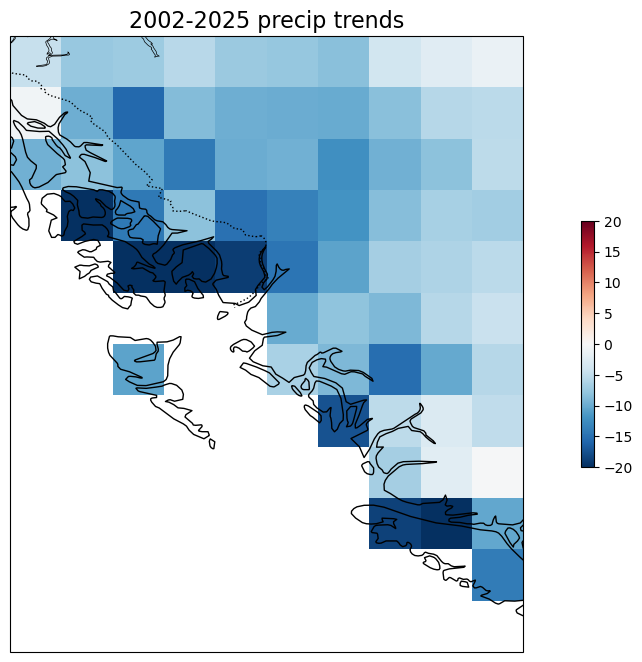

In [37]:


ols_slope = ds['TOTAL_PREC_trendslope'].mean(dim='month') * ns_to_year * 365.25

# Using .isel grabs by index. If you wanted degrees, use .sel(latitude=slice(...))
ols_slope_lim = ols_slope.isel(latitude=slice(138, 150), longitude=slice(45, 55))

# =====================================================================
# PLOT 2: Glacier-Free GRACE at 1 degree 
# =====================================================================

# Setup Cartopy Figure and Axis
plt.figure(figsize=(15, 8))
ax2 = plt.axes(projection=ccrs.PlateCarree())

# Add geographic context
ax2.coastlines(resolution='50m', color='black', linewidth=1)
ax2.add_feature(cfeature.BORDERS, linestyle=':', linewidth=1)
ax2.add_feature(cfeature.LAKES, facecolor='none', edgecolor='black', linewidth=0.5)

# Plotting - FIXED: Changed ax=ax_left to ax=ax2
C2 = ols_slope_lim.plot(
    ax=ax2, 
    transform=ccrs.PlateCarree(), 
    cmap='RdBu_r',add_colorbar=False, vmin=-20,vmax=20,
)
plt.colorbar(C2,shrink=.4)
plt.title('2002-2025 precip trends', fontsize=16)
plt.show()

In [56]:
LandFrac=xr.load_dataset('/Users/bilir/Desktop/CardamomScratch/LandFrac_coarsened_1x1.nc')

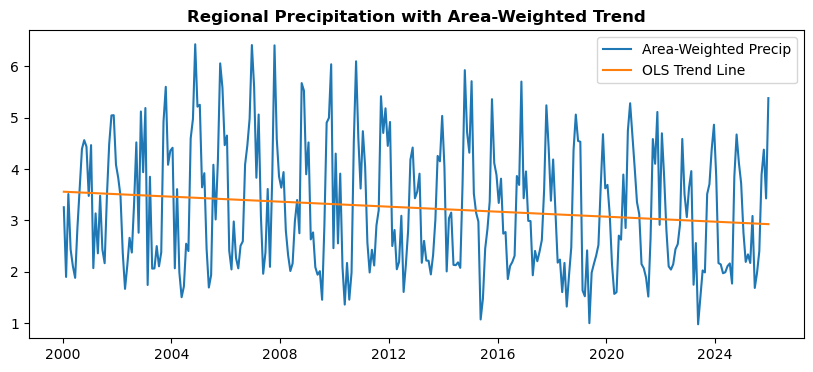

In [69]:
# 1. Area-weighted regional precipitation
regional_prec = (ds['TOTAL_PREC'] * LandFrac.LandArea).isel(latitude=slice(138, 150), longitude=slice(45, 55)).sum(['latitude', 'longitude']) / LandFrac.LandArea.isel(latitude=slice(138, 150), longitude=slice(45, 55)).sum(['latitude', 'longitude'])

# 2. Area-weighted mean trend
mean_trend = (ds['TOTAL_PREC_trendslope'] * LandFrac.LandArea).isel(latitude=slice(138, 150), longitude=slice(45, 55)).mean('month').sum(['latitude', 'longitude']) / LandFrac.LandArea.isel(latitude=slice(138, 150), longitude=slice(45, 55)).sum(['latitude', 'longitude'])

# 3. Monthly trend time series
trend_ts = np.arange(len(ds.time.data)) * (mean_trend * ns_to_year / 12).data

# 4. Center of the data
center = regional_prec.mean('time').data

# 5. Plotting
plt.figure(figsize=(10, 4))
plt.plot(ds.time, regional_prec, label='Area-Weighted Precip')

# Bulletproof centering: subtract the trend's own mean, then add the data's center
plt.plot(ds.time, trend_ts - trend_ts.mean() + center, label='OLS Trend Line')

plt.title('Regional Precipitation with Area-Weighted Trend', fontweight='bold')
plt.legend()
plt.show()

In [82]:
(mean_trend * ns_to_year * 365.25).data * np.arange(26)

array([  -0.        ,   -8.88788206,  -17.77576411,  -26.66364617,
        -35.55152822,  -44.43941028,  -53.32729234,  -62.21517439,
        -71.10305645,  -79.99093851,  -88.87882056,  -97.76670262,
       -106.65458467, -115.54246673, -124.43034879, -133.31823084,
       -142.2061129 , -151.09399496, -159.98187701, -168.86975907,
       -177.75764112, -186.64552318, -195.53340524, -204.42128729,
       -213.30916935, -222.19705141])

In [75]:
Abovev4=xr.load_dataset('/Users/bilir/Desktop/CardamomScratch/Concatenation_scripts/Final_Outputbase_Abovev4.nc')

In [77]:
Abovev4.TotalH2O_MRT.isel(quantile=2)

<xarray.DataArray 'TotalH2O_MRT' (latitude: 27, longitude: 94)> Size: 20kB
array([[           nan,            nan,            nan, ...,
        5.21850991e+02, 1.90439110e+02, 2.53317365e+02],
       [           nan,            nan,            nan, ...,
        1.07448696e+02, 3.38551910e+02, 1.17962502e+02],
       [           nan,            nan,            nan, ...,
        5.21388210e+02, 3.24559056e+02, 2.48371961e+02],
       ...,
       [           nan,            nan,            nan, ...,
                   nan,            nan, 4.70896658e+05],
       [           nan,            nan,            nan, ...,
        5.32269875e+05,            nan,            nan],
       [           nan,            nan,            nan, ...,
                   nan,            nan,            nan]], shape=(27, 94))
Coordinates:
  * longitude  (longitude) float64 752B -169.5 -168.5 -167.5 ... -77.5 -76.5
  * latitude   (latitude) float64 216B 48.5 49.5 50.5 51.5 ... 72.5 73.5 74.5
    quantile   float64 8B 0.5

In [83]:
import xarray as xr
import numpy as np

# 1. Define conversion constants
ns_to_year = 1e9 * 60 * 60 * 24 * 365.25

# 2. Extract and convert Mean Residence Time to years
MRT_years = Abovev4['TotalH2O_MRT'].isel(quantile=2) / 365.25

# 3. Subset the main dataset to match the spatial extent of Abovev4
# Using .sel with 'nearest' ensures the grids perfectly align without throwing dimension errors
ds_sub = ds[['TOTAL_PREC', 'TOTAL_PREC_detrended', 'TOTAL_PREC_trendslope']].sel(
    latitude=MRT_years.latitude, 
    longitude=MRT_years.longitude, 
    method='nearest'
)

# 4. Calculate the Annual Missing Precipitation Rate (L)
# Slope is (mm/day) per ns. 
# * ns_to_year -> (mm/day) missing per year
# * 365.25 -> (mm/year) missing per year
annual_loss_rate = ds_sub['TOTAL_PREC_trendslope'].mean(dim='month') * ns_to_year * 365.25

# 5. Calculate continuous parameters for the integration
T_max = float(ds['time'].dt.year.max() - ds['time'].dt.year.min()) # Usually 25 or 26 years

# Cap the residence time at T_max. 
# (If MRT is 50 years, we only have 25 years of trend data, so we cap it at 25)
MRT_capped = xr.where(MRT_years > T_max, T_max, MRT_years)

# 6. Compute the Hydrological Deficit using the continuous integral
# Formula: L * M * (T - M/2)
hydro_deficit = annual_loss_rate * MRT_capped * (T_max - (MRT_capped / 2.0))

# 7. Package everything into the new Dataset
ds_hydro = xr.Dataset({
    'TOTAL_PREC_trendslope': ds_sub['TOTAL_PREC_trendslope'],
    'TOTAL_PREC': ds_sub['TOTAL_PREC'],
    'TOTAL_PREC_detrended': ds_sub['TOTAL_PREC_detrended'],
    'MRT_years': MRT_years,
    'hydro_deficit': hydro_deficit
})

# Add some helpful metadata attributes
ds_hydro['MRT_years'].attrs['units'] = 'years'
ds_hydro['MRT_years'].attrs['description'] = 'Mean Residence Time of Total H2O (Quantile 2)'

ds_hydro['hydro_deficit'].attrs['units'] = 'mm'
ds_hydro['hydro_deficit'].attrs['description'] = f'Cumulative hydrological deficit over the residence time window, ending at year {int(ds.time.dt.year.max().item())}'

print("Hydrological Deficit Dataset successfully generated!")



Hydrological Deficit Dataset successfully generated!


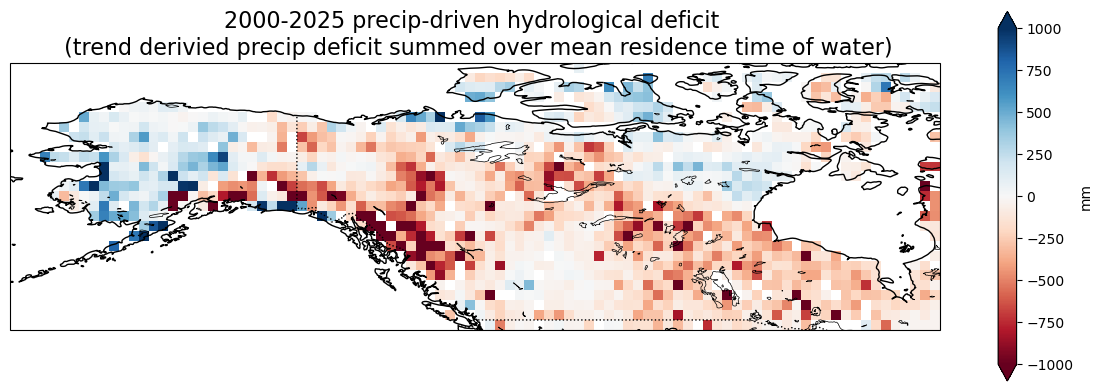

In [95]:
plt.figure(figsize=(15, 8))
ax2 = plt.axes(projection=ccrs.PlateCarree())

# Add geographic context
ax2.coastlines(resolution='50m', color='black', linewidth=1)
ax2.add_feature(cfeature.BORDERS, linestyle=':', linewidth=1)
ax2.add_feature(cfeature.LAKES, facecolor='none', edgecolor='black', linewidth=0.5)

# Plotting
C2 = ds_hydro['hydro_deficit'].plot.pcolormesh(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap='RdBu',
    vmin=-1000,
    vmax=1000,
    add_colorbar=True,
    cbar_kwargs={'shrink': 0.6, 'label': 'mm'}
)
plt.title('2000-2025 precip-driven hydrological deficit \n (trend derivied precip deficit summed over mean residence time of water)', fontsize=16)
plt.show()


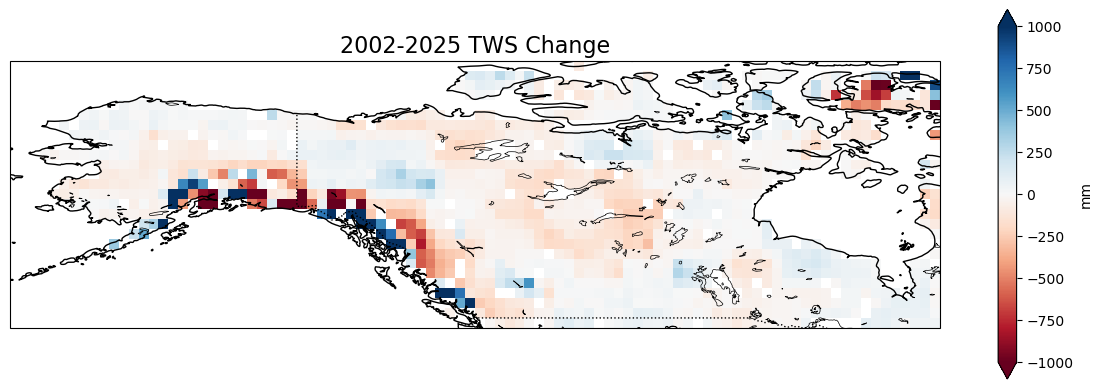

In [87]:
plt.figure(figsize=(15, 8))
ax2 = plt.axes(projection=ccrs.PlateCarree())

# Add geographic context
ax2.coastlines(resolution='50m', color='black', linewidth=1)
ax2.add_feature(cfeature.BORDERS, linestyle=':', linewidth=1)
ax2.add_feature(cfeature.LAKES, facecolor='none', edgecolor='black', linewidth=0.5)
data=Abovev4.Total_water.isel(quantile=2).groupby(Abovev4.time_pools.dt.year).mean() #Outputbase.Total_ice.isel(quantile=2).groupby(Outputbase.time_pools.dt.year).mean()


# 3. Extract the data slice (using xarray's .isel for the 2nd quantile index)
data_to_plot =data[dict(year=np.arange(12,26))].mean('year')-data[dict(year=np.arange(12))].mean('year')

# Plotting
C2 = data_to_plot.plot.pcolormesh(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap='RdBu',
    vmin=-1000,
    vmax=1000,
    add_colorbar=True,
    cbar_kwargs={'shrink': 0.6, 'label': 'mm'}
)
plt.title('2002-2025 TWS Change', fontsize=16)
plt.show()


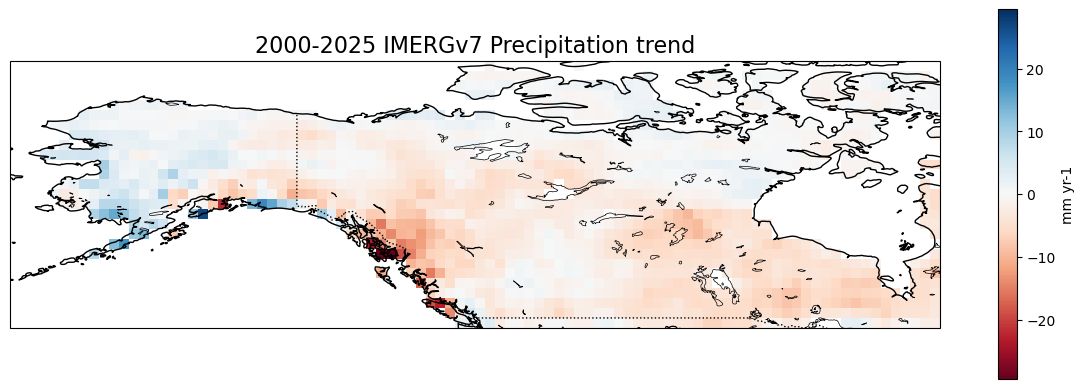

In [93]:
plt.figure(figsize=(15, 8))
ax2 = plt.axes(projection=ccrs.PlateCarree())

# Add geographic context
ax2.coastlines(resolution='50m', color='black', linewidth=1)
ax2.add_feature(cfeature.BORDERS, linestyle=':', linewidth=1)
ax2.add_feature(cfeature.LAKES, facecolor='none', edgecolor='black', linewidth=0.5)

# Plotting
C2 = (ds_hydro['TOTAL_PREC_trendslope'].mean('month')*ns_to_year*365.25).plot.pcolormesh(
    ax=ax2,
    transform=ccrs.PlateCarree(),
    cmap='RdBu',
    # vmin=-1000,
    # vmax=1000,
    add_colorbar=True,
    cbar_kwargs={'shrink': 0.6, 'label': 'mm yr-1'}
)
plt.title('2000-2025 IMERGv7 Precipitation trend', fontsize=16)
plt.show()


# SKT algorithm

### Random Forest

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Define your target and features (excluding SNOWFALL and SKT)
target = 'SKT'
features = ['T2M_avg', 'T2M_DTR', 'VPD', 'TOTAL_PREC', 'SSRD', 'STRD','WIND']

# ==========================================
# 1. Convert xarray to a pandas DataFrame
# ==========================================
print("Converting dataset to dataframe...")
# We select only the necessary variables, convert to a tabular format, and drop NaNs
df = ds[features + [target]].to_dataframe().dropna()

# Separate into predictors (X) and target (y)
X = df[features]
y = df[target]

# ==========================================
# 2. Train-Test Split
# ==========================================
print("Splitting data into train and test sets...")
# 1. Ensure your dataframe is sorted chronologically
# Assuming 'time' is one of the indices after flattening the xarray dataset
df = df.sort_index(level='time')

# 2. Define the cutoff date (e.g., separating the first 20 years from the last 5)
cutoff_date = pd.to_datetime('2020-12-31')

# 3. Split the data based on the time index
# Train on the "present" (2021-2025)
train_df = df[df.index.get_level_values('time') > cutoff_date]

# Test on the "past" (2000-2020) to simulate hindcasting
test_df = df[df.index.get_level_values('time') <= cutoff_date]

# 4. Separate features and targets
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print(f"Training on {len(X_train)} samples (Last 5 years)")
print(f"Testing on {len(X_test)} samples (Previous 20 years)")


Converting dataset to dataframe...
Splitting data into train and test sets...
Training on 1276260 samples (Last 5 years)
Testing on 5360292 samples (Previous 20 years)


In [6]:
# ==========================================
# 3. Train the Random Forest Regressor
# ==========================================
print("Training the Random Forest model...")
# n_jobs=-1 tells scikit-learn to use all available CPU cores to speed up training
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# ==========================================
# 4. Evaluate the Model
# ==========================================
print("Evaluating the model...")
y_pred = rf_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")

Training the Random Forest model...
Evaluating the model...
Mean Squared Error: 1.27
R-squared: 1.00


In [7]:
# Predict SKT for the entire valid dataset
print("Predicting across the full valid spatial domain...")
full_predictions = rf_model.predict(X)

# Assign predictions to a new column in our flattened DataFrame
df['SKT_PREDICTED'] = full_predictions

# Convert the DataFrame back to an xarray Dataset
# This automatically reshapes the data back into time x lat x lon
ds_predicted = df[['SKT_PREDICTED']].to_xarray()

# Merge the predicted variable back into your master dataset
ds = xr.merge([ds, ds_predicted])

# Add metadata for good measure
ds['SKT_PREDICTED'].attrs.update({'source': 'Random Forest Prediction', 'units': 'degrees Celsius'})

print("Done! 'SKT_PREDICTED' is now in your master dataset.")

Predicting across the full valid spatial domain...
Done! 'SKT_PREDICTED' is now in your master dataset.


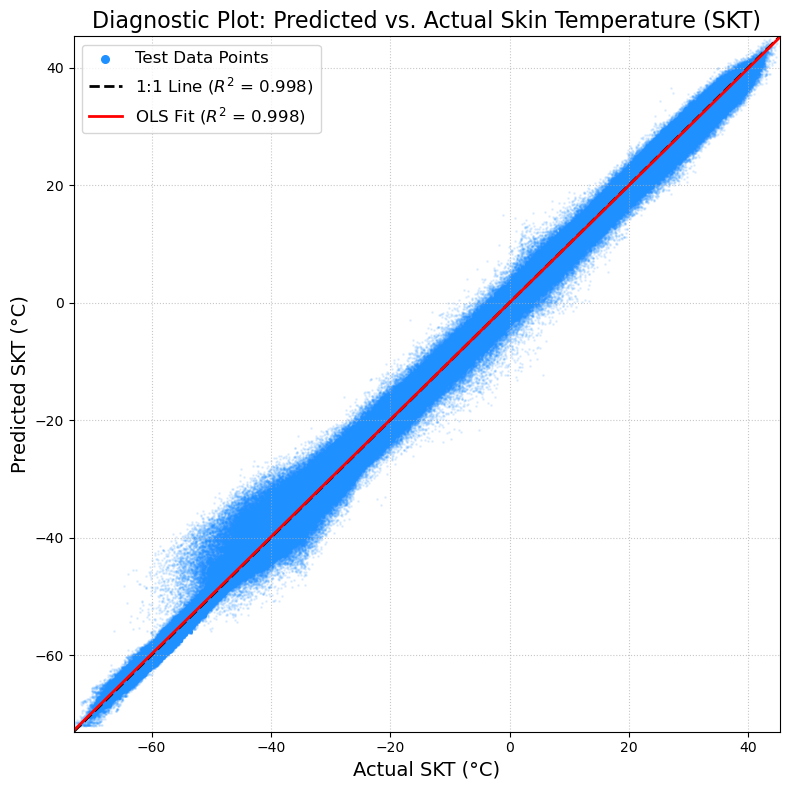

In [9]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import linregress
from sklearn.metrics import r2_score

# 1. Calculate R2 for the 1:1 line (Standard scikit-learn R2)
r2_1to1 = r2_score(y_test, y_pred)

# 2. Calculate OLS regression line and its R2 (Pearson's r squared)
slope, intercept, r_value, p_value, std_err = linregress(y_test, y_pred)
r2_ols = r_value**2

# 3. Set up the plot
plt.figure(figsize=(8, 8))

# Scatter plot of withheld test data
# Note: s=1 and alpha=0.1 help visualize density in massive climate datasets
plt.scatter(y_test, y_pred, alpha=0.1, s=1, color='dodgerblue', label='Test Data Points')

# Determine the min and max limits to make the plot perfectly square
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
limits = [min_val, max_val]

# Plot the 1:1 line
plt.plot(limits, limits, color='black', linestyle='--', linewidth=2, 
         label=f'1:1 Line ($R^2$ = {r2_1to1:.3f})')

# Plot the OLS line
ols_line = slope * np.array(limits) + intercept
plt.plot(limits, ols_line, color='red', linestyle='-', linewidth=2, 
         label=f'OLS Fit ($R^2$ = {r2_ols:.3f})')

# Formatting and aesthetics
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel('Actual SKT (°C)', fontsize=14)
plt.ylabel('Predicted SKT (°C)', fontsize=14)
plt.title('Diagnostic Plot: Predicted vs. Actual Skin Temperature (SKT)', fontsize=16)

# Create legend
legend = plt.legend(loc='upper left', fontsize=12)

for handle in legend.legend_handles:
    # Make all legend items fully opaque
    if hasattr(handle, 'set_alpha'):
        handle.set_alpha(1.0)
        
    # Increase marker size ONLY for the scatter plot points
    if hasattr(handle, 'set_sizes'):
        handle.set_sizes([30.0])
    
    # Ensure lines stay thick in the legend
    elif hasattr(handle, 'set_linewidth'):
        handle.set_linewidth(2.0)
        
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()

# Save and/or show
# plt.savefig('SKT_RF_Diagnostic_Plot.png', dpi=300)
plt.show()

### With a GAM (better for out-of-time extrapolation)

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from sklearn.metrics import mean_squared_error, r2_score
from pygam import LinearGAM, s, l, te

# Define your target and features
target = 'SKT'
features = ['T2M_avg', 'T2M_DTR', 'VPD', 'TOTAL_PREC', 'SSRD', 'STRD','WIND']


# ==========================================
# 1. Convert xarray to a pandas DataFrame
# ==========================================
print("Converting dataset to dataframe...")
# We select only the necessary variables, convert to a tabular format, and drop NaNs
df = ds[features + [target]].to_dataframe().dropna()

# ==========================================
# 1. Temporal Train-Test Split (Hindcast Simulation)
# ==========================================
print("Splitting data temporally...")
# Ensure dataframe is sorted by time
df = df.sort_index(level='time')

# Train on the "present" (e.g., 2021-2025)
cutoff_date = pd.to_datetime('2004-12-31')
train_df = df[df.index.get_level_values('time') > cutoff_date]

# Test on the "past" (e.g., 2000-2020)
test_df = df[df.index.get_level_values('time') <= cutoff_date]

X_train = train_df[features].values # pygam expects numpy arrays
y_train = train_df[target].values
X_test = test_df[features].values
y_test = test_df[target].values

# ==========================================
# 2. Build and Train the GAM
# ========================================== gam = LinearGAM(te(0, 2) + s(1) + ...)
print("Training the GAM (this may take a moment on large datasets)...")
# We apply a spline s() to each of the 6 features. 
# n_splines controls flexibility (default is usually 20, we use 10 for speed on large data)
# Features index reference: 
# 0: T2M_avg | 1: T2M_DTR | 2: VPD | 3: TOTAL_PREC | 4: SSRD | 5: STRD | 6: WIND

gam = LinearGAM(
    # 1. The Undisputed Baseline
    l(0) +                        # Linear: T2M_avg (Locks in the 1:1 core relationship)
    
    # 2. The Radiation Interactions (Modeling the residual warming/cooling)
    te(0, 4, n_splines=(5, 5)) +  # Tensor: T2M_avg & SSRD
    te(0, 5, n_splines=(5, 5)) +  # Tensor: T2M_avg & STRD
    
    # 3. The Independent Drivers (Stiffened to prevent overfitting!)
    s(2, n_splines=4) +           # Spline: VPD (Forced to be a smooth curve)
    s(6, n_splines=4) +           # Spline: WIND (Forced to be a smooth curve)
    s(3, n_splines=4) +           # Spline: TOTAL_PREC 
    s(1, n_splines=4)             # Spline: T2M_DTR
)

# Note: For massive datasets, you might want to use a random subsample for training
# e.g., gam.fit(X_train[::10], y_train[::10]) to train on every 10th row
gam.fit(X_train, y_train)

# ==========================================
# 3. Predict and Evaluate
# ==========================================
print("Evaluating the model on historical test data...")
y_pred = gam.predict(X_test)

r2_1to1 = r2_score(y_test, y_pred)
slope, intercept, r_value, p_value, std_err = linregress(y_test, y_pred)
r2_ols = r_value**2

print(f"1:1 R-squared (NSE): {r2_1to1:.3f}")
print(f"OLS R-squared (Pearson): {r2_ols:.3f}")

Converting dataset to dataframe...
Splitting data temporally...
Training the GAM (this may take a moment on large datasets)...
Evaluating the model on historical test data...
1:1 R-squared (NSE): 0.998
OLS R-squared (Pearson): 0.998


In [5]:
import xarray as xr

# ==========================================
# 4. Map Predictions Back to Xarray
# ==========================================
print("Predicting across the full valid spatial domain...")

# Extract the full feature set as a NumPy array for the GAM
X_full = df[features].values

# Generate predictions using the trained GAM
full_predictions = gam.predict(X_full)

# Assign predictions to a new column in our flattened DataFrame
df['SKT_PREDICTED_GAM7'] = full_predictions

# Convert the DataFrame back to an xarray Dataset
# Since the dataframe still retains its latitude, longitude, and time multi-index, 
# this automatically reshapes the data back into a 3D cube.
ds_predicted = df[['SKT_PREDICTED_GAM7']].to_xarray()

# Merge the predicted variable back into your master dataset
ds = xr.merge([ds, ds_predicted])

# Add metadata reflecting the new model
ds['SKT_PREDICTED_GAM7'].attrs.update({
    'source': 'Generalized Additive Model (GAM) Prediction', 
    'units': 'degrees Celsius'
})

print("Done! 'SKT_PREDICTED_GAM7' is now in your master dataset.")

Predicting across the full valid spatial domain...
Done! 'SKT_PREDICTED_GAM7' is now in your master dataset.


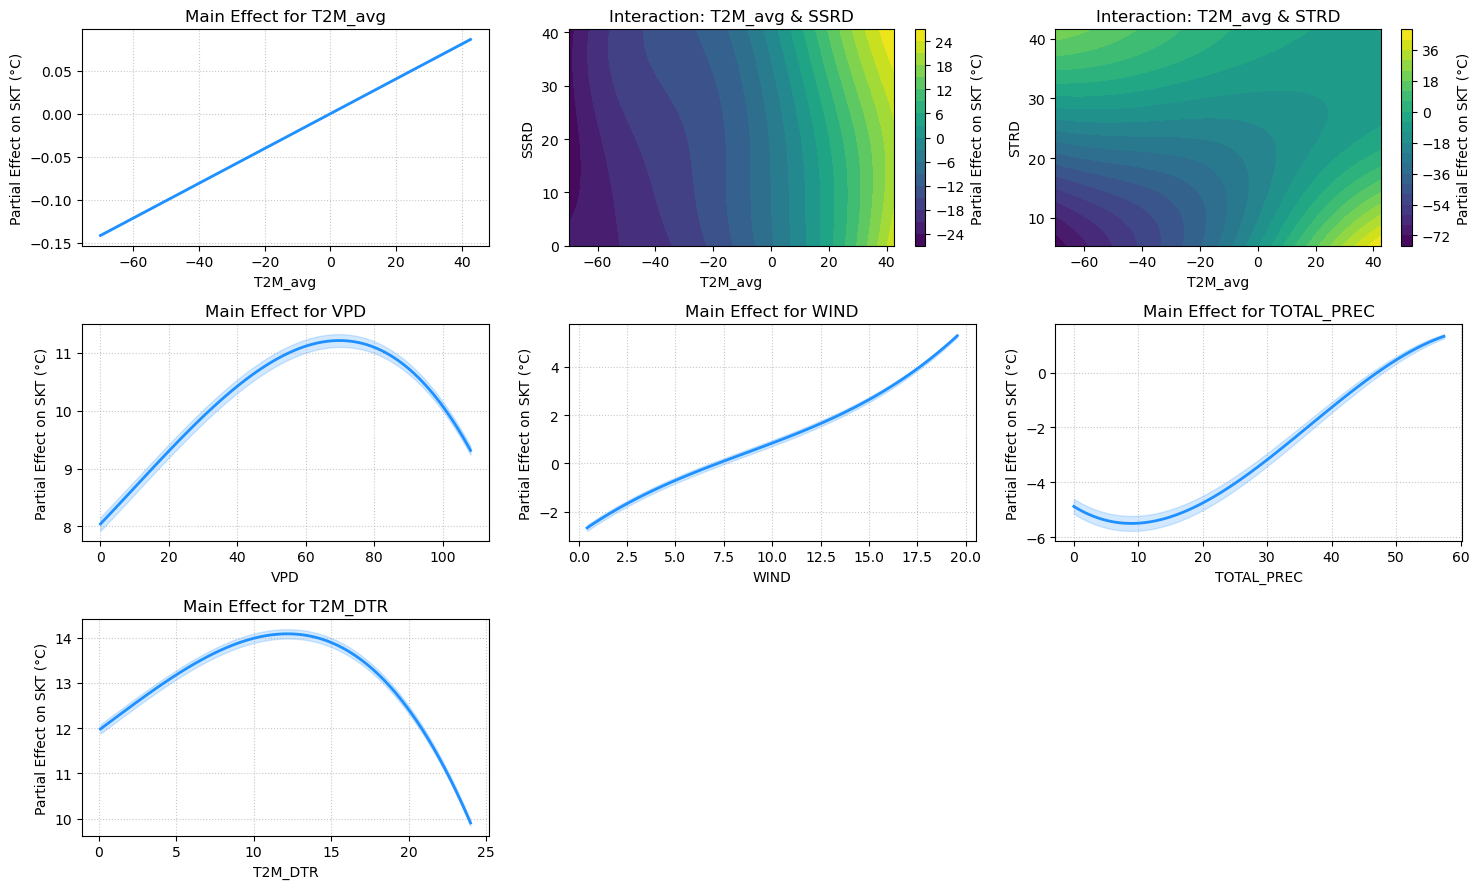

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Dynamically count how many non-intercept terms the model actually has
num_plots = sum(1 for term in gam.terms if not term.isintercept)

# 2. Calculate grid dimensions (3 columns, as many rows as needed)
cols = 3
rows = int(np.ceil(num_plots / cols))

# Set up the dynamic grid
fig, axs = plt.subplots(rows, cols, figsize=(15, 3 * rows))
axs = np.array(axs).flatten() # Ensure it's always a flat list, even for 1 row

plot_idx = 0
for i, term in enumerate(gam.terms):
    # Skip the intercept term
    if term.isintercept:
        continue
    
    # Safety catch to prevent index errors
    if plot_idx >= len(axs):
        break
        
    ax = axs[plot_idx]
    
    # ==========================================
    # 1. Plotting 2D Tensors (te)
    # ==========================================
    if len(np.atleast_1d(term.feature)) == 2:
        f1, f2 = term.feature
        
        # Use pygam's built-in meshgrid generation
        XX = gam.generate_X_grid(term=i, meshgrid=True, n=50)
        Z = gam.partial_dependence(term=i, X=XX, meshgrid=True)
        
        # Create a contour map
        contour = ax.contourf(XX[0], XX[1], Z, cmap='viridis', levels=20)
        fig.colorbar(contour, ax=ax, orientation='vertical', label='Partial Effect on SKT (°C)')
        
        ax.set_xlabel(features[f1], fontsize=10)
        ax.set_ylabel(features[f2], fontsize=10)
        ax.set_title(f'Interaction: {features[f1]} & {features[f2]}', fontsize=12)
        
    # ==========================================
    # 2. Plotting 1D Splines (s)
    # ==========================================
    else:
        # Extract the single feature index
        f1 = term.feature if isinstance(term.feature, int) else term.feature[0]
        
        # Generate 1D grid and calculate dependence
        XX = gam.generate_X_grid(term=i)
        pdep, confidence = gam.partial_dependence(term=i, X=XX, width=0.95)
        
        # Plot the curve and the 95% confidence intervals
        ax.plot(XX[:, f1], pdep, color='dodgerblue', linewidth=2)
        ax.fill_between(XX[:, f1], confidence[:, 0], confidence[:, 1], alpha=0.2, color='dodgerblue')
        
        ax.set_xlabel(features[f1], fontsize=10)
        ax.set_ylabel('Partial Effect on SKT (°C)', fontsize=10)
        ax.set_title(f'Main Effect for {features[f1]}', fontsize=12)
        ax.grid(True, linestyle=':', alpha=0.7)
        
    plot_idx += 1

# Clean up any leftover empty subplots if the grid isn't perfectly full
for j in range(plot_idx, len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout()
plt.show()

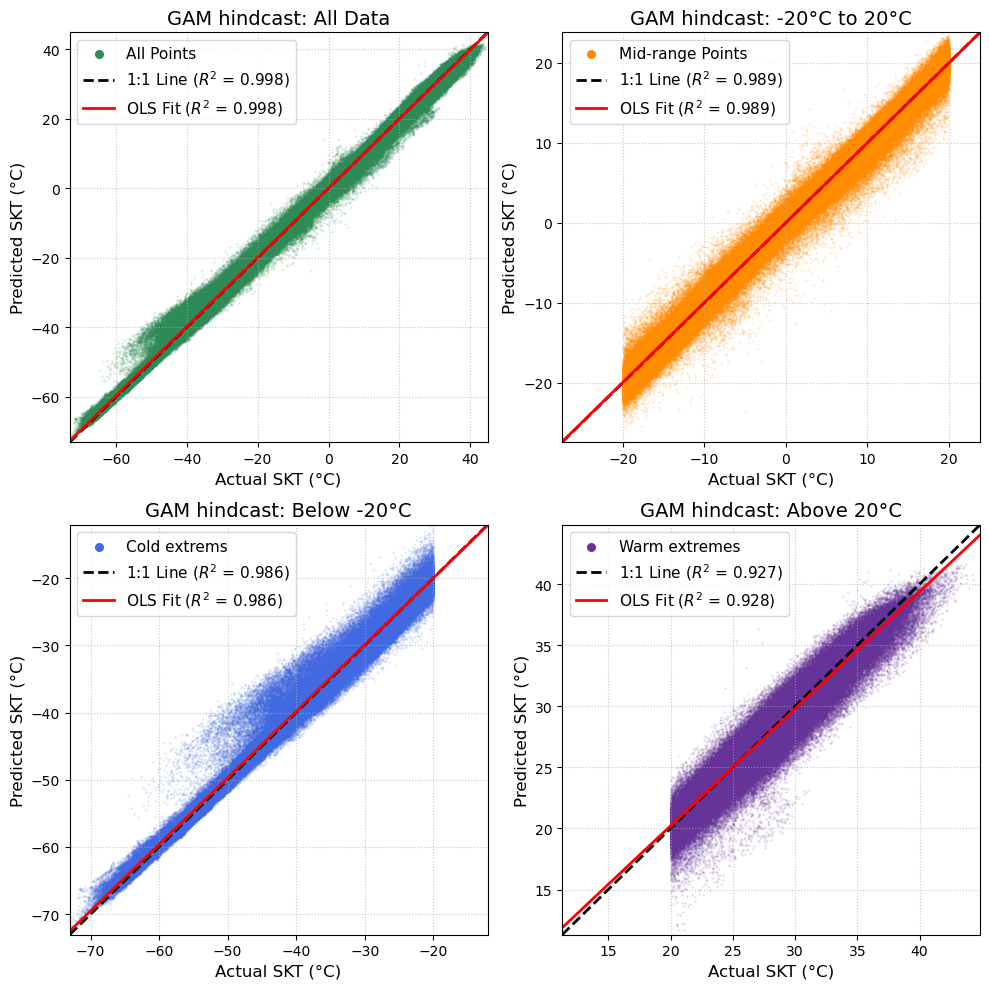

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score
from scipy.stats import linregress

# Define the masks, colors, and titles for our 4 GAM subplots
plot_configs = [
    {
        "mask": np.ones_like(y_test, dtype=bool), # All True (No filter)
        "title": "GAM hindcast: All Data",
        "color": "seagreen",
        "label": "All Points"
    },
    {
        "mask": (y_test >= -20) & (y_test <= 20),
        "title": "GAM hindcast: -20°C to 20°C",
        "color": "darkorange",
        "label": "Mid-range Points"
    },
    {
        "mask": y_test < -20,
        "title": "GAM hindcast: Below -20°C",
        "color": "royalblue",
        "label": "Cold extrems"
    },
    {
        "mask": y_test > 20,
        "title": "GAM hindcast: Above 20°C",
        "color": "rebeccapurple", 
        "label": "Warm extremes"
    }
]

# Set up a 2x2 figure grid
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs = axs.flatten()

# Loop through each configuration and plot
for ax, config in zip(axs, plot_configs):
    # Apply the mask to isolate the specific subset of data
    yt_sub = y_test[config["mask"]]
    yp_sub = y_pred[config["mask"]]
    
    # Recalculate metrics for ONLY this subset
    r2_1to1_sub = r2_score(yt_sub, yp_sub)
    slope, intercept, r_value, p_value, std_err = linregress(yt_sub, yp_sub)
    r2_ols_sub = r_value**2
    
    # Scatter plot
    ax.scatter(yt_sub, yp_sub, alpha=0.1, s=1, color=config["color"], label=config["label"])
    
    # Determine limits dynamically based on the subset to make it perfectly square
    min_val = min(yt_sub.min(), yp_sub.min())
    max_val = max(yt_sub.max(), yp_sub.max())
    limits = [min_val, max_val]
    
    # Plot the 1:1 line
    ax.plot(limits, limits, color='black', linestyle='--', linewidth=2, 
             label=f'1:1 Line ($R^2$ = {r2_1to1_sub:.3f})')
    
    # Plot the OLS fit line
    ols_line = slope * np.array(limits) + intercept
    ax.plot(limits, ols_line, color='red', linestyle='-', linewidth=2, 
             label=f'OLS Fit ($R^2$ = {r2_ols_sub:.3f})')
    
    # Formatting
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_xlabel('Actual SKT (°C)', fontsize=12)
    ax.set_ylabel('Predicted SKT (°C)', fontsize=12)
    ax.set_title(config["title"], fontsize=14)
    
    # Fixed Legend
    legend = ax.legend(loc='upper left', fontsize=11)
    for handle in legend.legend_handles:
        if hasattr(handle, 'set_alpha'):
            handle.set_alpha(1.0)
        if hasattr(handle, 'set_sizes'):
            handle.set_sizes([30.0])
        elif hasattr(handle, 'set_linewidth'):
            handle.set_linewidth(2.0)
            
    ax.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

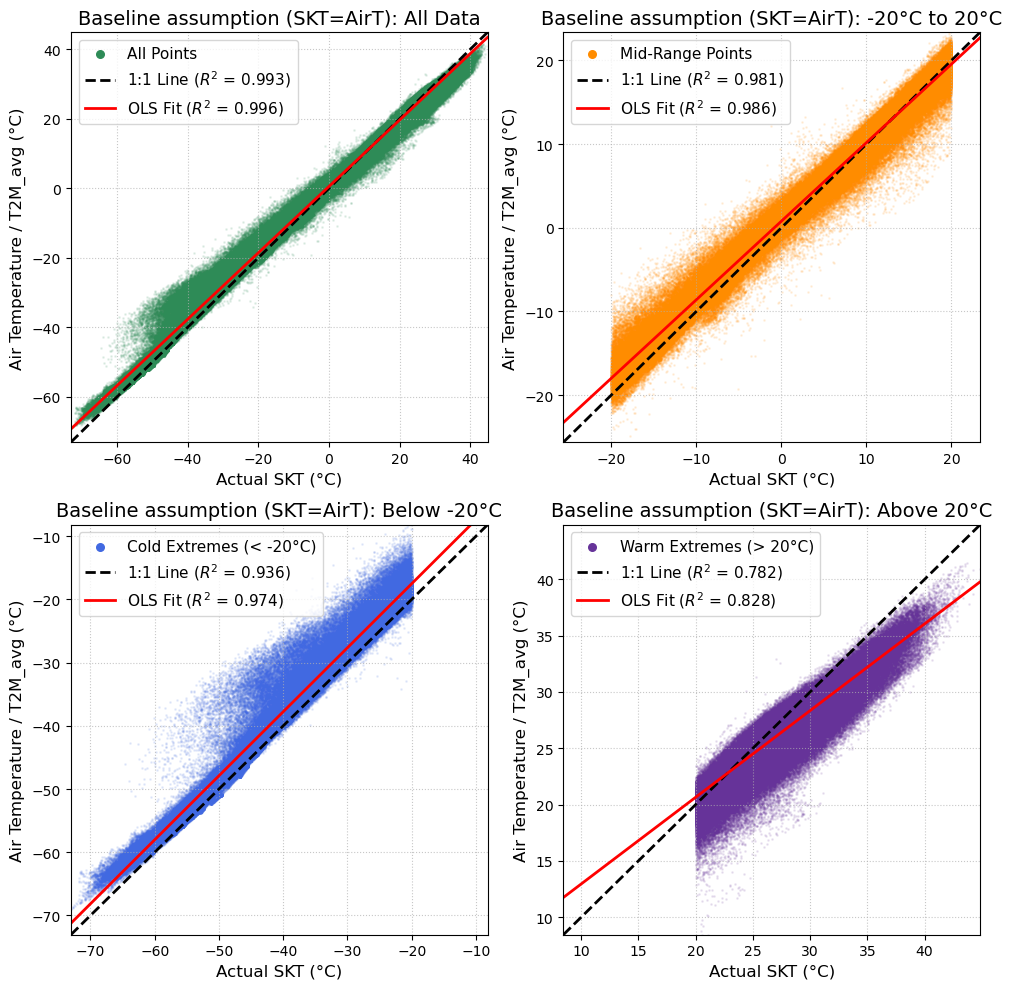

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score
from scipy.stats import linregress

# 1. Extract Air Temperature (T2M_avg) from the test set as our baseline prediction
y_baseline = X_test[:, 0]

# 2. Define the masks, colors, and titles for our 4 subplots
plot_configs = [
    {
        "mask": np.ones_like(y_test, dtype=bool), # All True (No filter)
        "title": "Baseline assumption (SKT=AirT): All Data",
        "color": "seagreen",
        "label": "All Points"
    },
    {
        "mask": (y_test >= -20) & (y_test <= 20),
        "title": "Baseline assumption (SKT=AirT): -20°C to 20°C",
        "color": "darkorange",
        "label": "Mid-Range Points"
    },
    {
        "mask": y_test < -20,
        "title": "Baseline assumption (SKT=AirT): Below -20°C",
        "color": "royalblue",
        "label": "Cold Extremes (< -20°C)"
    },
    {
        "mask": y_test > 20,
        "title": "Baseline assumption (SKT=AirT): Above 20°C",
        "color": "rebeccapurple", 
        "label": "Warm Extremes (> 20°C)"
    }
]

# 3. Set up a 2x2 figure grid
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs = axs.flatten()

# 4. Loop through each configuration and plot
for ax, config in zip(axs, plot_configs):
    # Apply the mask to isolate the specific subset of data
    yt_sub = y_test[config["mask"]]
    yp_sub = y_baseline[config["mask"]]
    
    # Recalculate metrics for ONLY this subset
    r2_1to1_sub = r2_score(yt_sub, yp_sub)
    slope, intercept, r_value, p_value, std_err = linregress(yt_sub, yp_sub)
    r2_ols_sub = r_value**2
    
    # Scatter plot
    ax.scatter(yt_sub, yp_sub, alpha=0.1, s=1, color=config["color"], label=config["label"])
    
    # Determine limits dynamically based on the subset to make it square
    min_val = min(yt_sub.min(), yp_sub.min())
    max_val = max(yt_sub.max(), yp_sub.max())
    limits = [min_val, max_val]
    
    # Plot the lines
    ax.plot(limits, limits, color='black', linestyle='--', linewidth=2, 
             label=f'1:1 Line ($R^2$ = {r2_1to1_sub:.3f})')
    
    ols_line = slope * np.array(limits) + intercept
    ax.plot(limits, ols_line, color='red', linestyle='-', linewidth=2, 
             label=f'OLS Fit ($R^2$ = {r2_ols_sub:.3f})')
    
    # Formatting
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_xlabel('Actual SKT (°C)', fontsize=12)
    ax.set_ylabel('Air Temperature / T2M_avg (°C)', fontsize=12)
    ax.set_title(config["title"], fontsize=14)
    
    # Fixed Legend
    legend = ax.legend(loc='upper left', fontsize=11)
    for handle in legend.legend_handles:
        if hasattr(handle, 'set_alpha'):
            handle.set_alpha(1.0)
        if hasattr(handle, 'set_sizes'):
            handle.set_sizes([30.0])
        elif hasattr(handle, 'set_linewidth'):
            handle.set_linewidth(2.0)
            
    ax.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

# Try to predict skt from UKESM

In [56]:
# import os
# import subprocess
# import glob

# # 1. Define the directory where your .sh files are located
# # (Use '.' if they are in the same folder as your notebook)
# script_dir = '/Users/bilir/Desktop/CardamomScratch/WIE-MIP_drivers/testcase_1pctCO2UKESM/' 

# # 2. Find all wget scripts in the directory
# wget_scripts = glob.glob(os.path.join(script_dir, 'wget_script_*.sh'))

# if not wget_scripts:
#     print("No wget scripts found in the directory.")
# else:
#     print(f"Found {len(wget_scripts)} scripts. Starting download...\n")
    
#     for script in wget_scripts:
#         script_name = os.path.basename(script)
#         print(f"--- Executing: {script_name} ---")
        
#         try:
#             # Step A: Make the script executable (chmod +x)
#             # This is required on Mac/Linux before running a bash script
#             os.chmod(script, 0o755) 
            
#             # Step B: Run the script and stream the output to the notebook
#             # Note: The '-H' flag is used to skip OpenID authentication if the node allows anonymous downloads for CMIP6
#             process = subprocess.Popen(
#                 ['bash', script, '-H'], 
#                 stdout=subprocess.PIPE, 
#                 stderr=subprocess.STDOUT,
#                 text=True
#             )
            
#             # Print the terminal output line-by-line so you can monitor progress
#             for line in process.stdout:
#                 print(line.strip())
                
#             process.wait()
            
#             if process.returncode == 0:
#                 print(f"✅ Successfully finished {script_name}\n")
#             else:
#                 print(f"❌ Error executing {script_name}. Return code: {process.returncode}\n")
                
#         except Exception as e:
#             print(f"⚠️ Failed to run {script_name}. Error: {e}\n")

# print("All downloads complete!")

Found 10 scripts. Starting download...

--- Executing: wget_script_2026-6-27_20-20-11.sh ---
Running wget_script_2026-6-27_20-20-11.sh version: 1.3.2
Use wget_script_2026-6-27_20-20-11.sh -h for help.

Script created for 2 file(s)
(The count won't match if you manually edit this file!)



Retrieving Federation Certificates...--2026-06-27 20:23:58--  https://github.com/ESGF/esgf-dist/raw/master/installer/certs/esg-truststore.ts
Resolving github.com (github.com)... 140.82.116.3
Connecting to github.com (github.com)|140.82.116.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/ESGF/esgf-dist/master/installer/certs/esg-truststore.ts [following]
--2026-06-27 20:23:59--  https://raw.githubusercontent.com/ESGF/esgf-dist/master/installer/certs/esg-truststore.ts
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8002::154, 2606:50c0:8003::154, 2606:50c0:8000::154, ...
Connecting to raw.githubusercontent.co

In [12]:
# import os
# import xarray as xr

# # 1. Define the directory containing your NetCDF files
# data_dir = '/Users/bilir/Desktop/CardamomScratch/WIE-MIP_drivers/testcase_1pctCO2UKESM'

# # 2. Define the exact CMIP6 variables you downloaded
# var_names = ['huss', 'pr', 'ps', 'rlds', 'rsds', 'sfcWind', 'tas', 'tasmax', 'tasmin', 'ts']

# # 3. Loop through, load the chunks for each variable, and store them
# datasets = {}
# for var in var_names:
#     # Use a wildcard (*) to grab both the 1850-1949 and 1950-1999 files
#     file_pattern = os.path.join(data_dir, f"{var}_Amon_UKESM1-0-LL_1pctCO2_r1i1p1f2_gn_*.nc")
    
#     # open_mfdataset magically stitches the time chunks together
#     ds_var = xr.open_mfdataset(file_pattern, combine='by_coords')
    
#     # THE FIX: Drop the conflicting 'height' coordinate if it exists
#     if 'height' in ds_var.coords:
#         ds_var = ds_var.drop_vars('height')
        
#     datasets[var] = ds_var[var]

# # 4. Merge all individual variables into one master raw dataset
# ds_raw = xr.merge(datasets.values())

# ds_raw=xr.load_dataset('/Users/bilir/Desktop/CardamomScratch/WIE-MIP_drivers/testcase_1pctCO2UKESM/')
# print("✅ Successfully loaded and stitched raw CMIP6 data!")
# print(ds_raw)

✅ Successfully loaded and stitched raw CMIP6 data!
<xarray.Dataset> Size: 2GB
Dimensions:  (time: 1800, lat: 144, lon: 192)
Coordinates:
  * time     (time) object 14kB 1850-01-16 00:00:00 ... 1999-12-16 00:00:00
  * lat      (lat) float64 1kB -89.38 -88.12 -86.88 -85.62 ... 86.88 88.12 89.38
  * lon      (lon) float64 2kB 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1
Data variables:
    huss     (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    pr       (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    ps       (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    rlds     (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    rsds     (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    sfcWind  (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    tas      (time, lat, lon) 

In [13]:
# 1. Initialize a clean Dataset for CARDAMOM
ds_cardamom = xr.Dataset()

# --- TEMPERATURES (Convert Kelvin to Celsius) ---
# Formula: C = K - 273.15
ds_cardamom['T2M_avg'] = ds_raw['tas'] - 273.15
ds_cardamom['T2M_avg'].attrs['units'] = 'degC'

ds_cardamom['T2M_MAX'] = ds_raw['tasmax'] - 273.15
ds_cardamom['T2M_MAX'].attrs['units'] = 'degC'

ds_cardamom['T2M_MIN'] = ds_raw['tasmin'] - 273.15
ds_cardamom['T2M_MIN'].attrs['units'] = 'degC'

# DTR (Delta T is identical in Kelvin and Celsius, so we just subtract)
ds_cardamom['T2M_DTR'] = ds_raw['tasmax'] - ds_raw['tasmin']
ds_cardamom['T2M_DTR'].attrs['units'] = 'degC'

# Also bringing in TS (Skin Temp) for your GAM validation later
ds_cardamom['SKT'] = ds_raw['ts'] - 273.15
ds_cardamom['SKT'].attrs['units'] = 'degC'


# --- RADIATION (Convert W m-2 to MJ m-2 day-1) ---
# Formula: 1 W/m2 = 1 J/s/m2. Multiply by 86400 (s/day), divide by 1,000,000 (J to MJ) => * 0.0864
ds_cardamom['SSRD'] = ds_raw['rsds'] * 0.0864
ds_cardamom['SSRD'].attrs['units'] = 'MJ m-2 day-1'

ds_cardamom['STRD'] = ds_raw['rlds'] * 0.0864
ds_cardamom['STRD'].attrs['units'] = 'MJ m-2 day-1'


# --- PRECIPITATION (Convert kg m-2 s-1 to mm day-1) ---
# Formula: 1 kg m-2 is 1 mm. Multiply by 86400 seconds in a day.
ds_cardamom['TOTAL_PREC'] = ds_raw['pr'] * 86400.0
ds_cardamom['TOTAL_PREC'].attrs['units'] = 'mm day-1'


# --- WIND SPEED (Native unit is correct) ---
ds_cardamom['WIND'] = ds_raw['sfcWind']
ds_cardamom['WIND'].attrs['units'] = 'm s-1'


# --- VAPOR PRESSURE DEFICIT (VPD) ---
# CMIP6 native ps is already Pascals (Pa), and native huss is already kg/kg!
def scifun_h2o_saturation_pressure(T_C):
    """ Returns water vapour saturation pressure in kPa """
    return (6.11 * (10**(7.5 * T_C / (237.3 + T_C)))) / 10.0

def calc_actual_vapor_pressure(q, p_pa):
    """ Returns actual vapor pressure in kPa """
    ea_pa = (q * p_pa) / (0.622 + 0.378 * q)
    return ea_pa / 1000.0

# 1. Actual Vapor Pressure (ea) from specific humidity and surface pressure
ea_kpa = calc_actual_vapor_pressure(ds_raw['huss'], ds_raw['ps'])

# 2. Saturation Vapor Pressure (esat) from Maximum Daily Temperature (in Celsius)
esat_kpa = scifun_h2o_saturation_pressure(ds_cardamom['T2M_MAX'])

# 3. Calculate VPD in kPa, then multiply by 10 to convert to hPa
ds_cardamom['VPD'] = (esat_kpa - ea_kpa) * 10.0
ds_cardamom['VPD'].attrs['units'] = 'hPa'


print("✅ Successfully generated all CARDAMOM drivers!")
print(ds_cardamom)

✅ Successfully generated all CARDAMOM drivers!
<xarray.Dataset> Size: 2GB
Dimensions:     (time: 1800, lat: 144, lon: 192)
Coordinates:
  * time        (time) object 14kB 1850-01-16 00:00:00 ... 1999-12-16 00:00:00
  * lat         (lat) float64 1kB -89.38 -88.12 -86.88 ... 86.88 88.12 89.38
  * lon         (lon) float64 2kB 0.9375 2.812 4.688 6.562 ... 355.3 357.2 359.1
Data variables:
    T2M_avg     (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    T2M_MAX     (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    T2M_MIN     (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    T2M_DTR     (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    SKT         (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    SSRD        (time, lat, lon) float32 199MB dask.array<chunksize=(1, 144, 192), meta=np.ndarray>
    STRD   

In [34]:
import xarray as xr
import pandas as pd
import numpy as np

print("Starting chunked GAM prediction to save memory...\n")

# (Optional safety check): Rename TS to SKT if you haven't already in ds_cardamom
if 'TS' in ds_cardamom:
    ds_cardamom = ds_cardamom.rename({'TS': 'SKT'})

# Ensure the features are in the exact same order as your training script
features = ['T2M_avg', 'T2M_DTR', 'VPD', 'TOTAL_PREC', 'SSRD', 'STRD', 'WIND']

# We want 50-year chunks. 50 years * 12 months = 600 time steps.
time_steps = len(ds_cardamom.time)
chunk_size = 600 

# List to hold our finished xarray chunks
predicted_chunks = []

for start_idx in range(0, time_steps, chunk_size):
    end_idx = min(start_idx + chunk_size, time_steps)
    print(f"Processing time steps {start_idx} to {end_idx - 1}...")
    
    # 1. Slice the xarray dataset to just this 50-year chunk
    ds_chunk = ds_cardamom.isel(time=slice(start_idx, end_idx))
    
    # 2. Convert ONLY this chunk to a DataFrame and drop NaNs
    df_chunk = ds_chunk[features + ['SKT']].to_dataframe().dropna()
    
    # 3. Extract features and predict using the frozen ERA5 GAM
    X_chunk = df_chunk[features].values
    df_chunk['SKT_PREDICTED_GAM2'] = gam.predict(X_chunk)
    
    # 4. Convert this predicted chunk back to an xarray Dataset
    ds_pred_chunk = df_chunk[['SKT', 'SKT_PREDICTED_GAM2']].to_xarray()
    
    # 5. Append to our list of finished datasets
    predicted_chunks.append(ds_pred_chunk)
    
    # Free up RAM before the next loop
    del ds_chunk, df_chunk, X_chunk

print("\nAll chunks processed! Concatenating back into a single spatial dataset...")

# Stitch the 3 chunks back together along the time axis
ds_diagnostics = xr.concat(predicted_chunks, dim='time')

# Add metadata for clarity
ds_diagnostics['SKT_PREDICTED_GAM2'].attrs.update({
    'source': 'Generalized Additive Model (GAM) trained on ERA5',
    'units': 'degrees Celsius'
})
ds_diagnostics['SKT'].attrs.update({
    'source': 'Raw UKESM1 CMIP6 output (Validation Truth)',
    'units': 'degrees Celsius'
})

print("Done! 'ds_diagnostics' is ready for validation.")
print(ds_diagnostics)

Starting chunked GAM prediction to save memory...

Processing time steps 0 to 599...
Processing time steps 600 to 1199...
Processing time steps 1200 to 1799...

All chunks processed! Concatenating back into a single spatial dataset...
Done! 'ds_diagnostics' is ready for validation.
<xarray.Dataset> Size: 597MB
Dimensions:             (time: 1800, lat: 144, lon: 192)
Coordinates:
  * time                (time) object 14kB 1850-01-16 00:00:00 ... 1999-12-16...
  * lat                 (lat) float64 1kB -89.38 -88.12 -86.88 ... 88.12 89.38
  * lon                 (lon) float64 2kB 0.9375 2.812 4.688 ... 357.2 359.1
Data variables:
    SKT                 (time, lat, lon) float32 199MB -24.47 -24.46 ... 5.266
    SKT_PREDICTED_GAM2  (time, lat, lon) float64 398MB -27.87 -27.87 ... 3.333


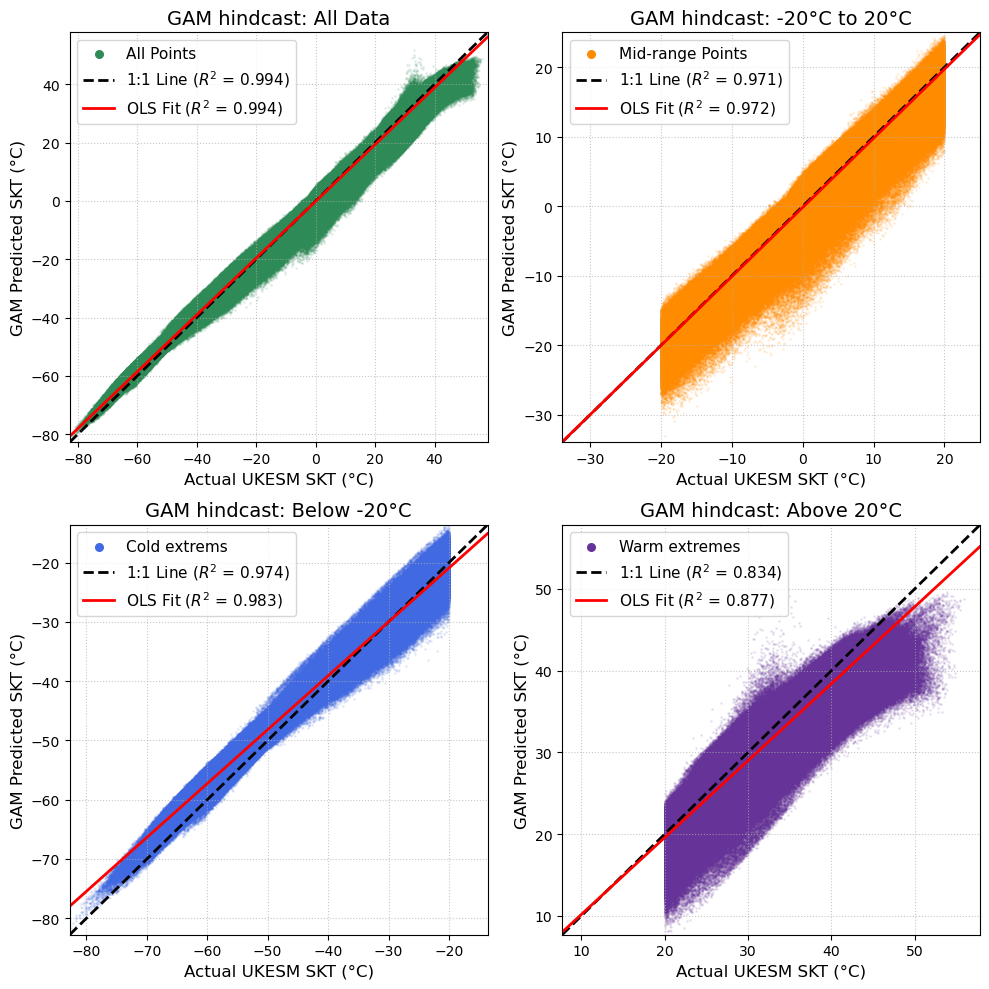

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
from scipy.stats import linregress

# --- THE FIX ---
# Extract just the two variables we need from the master diagnostics dataset,
# flatten them into a dataframe, and drop any NaNs (like ocean pixels).
df_plot = ds_diagnostics[['SKT', 'SKT_PREDICTED_GAM2']].to_dataframe().dropna()

y_actual = df_plot['SKT'].values
y_pred_gam = df_plot['SKT_PREDICTED_GAM2'].values
# ---------------

# Define the masks, colors, and titles for our 4 GAM subplots
plot_configs = [
    {
        "mask": np.ones_like(y_actual, dtype=bool), # All True (No filter)
        "title": "GAM hindcast: All Data",
        "color": "seagreen",
        "label": "All Points"
    },
    {
        "mask": (y_actual >= -20) & (y_actual <= 20),
        "title": "GAM hindcast: -20°C to 20°C",
        "color": "darkorange",
        "label": "Mid-range Points"
    },
    {
        "mask": y_actual < -20,
        "title": "GAM hindcast: Below -20°C",
        "color": "royalblue",
        "label": "Cold extrems"
    },
    {
        "mask": y_actual > 20,
        "title": "GAM hindcast: Above 20°C",
        "color": "rebeccapurple", 
        "label": "Warm extremes"
    }
]

# Set up a 2x2 figure grid
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs = axs.flatten()

# Loop through each configuration and plot
for ax, config in zip(axs, plot_configs):
    # Apply the mask to isolate the specific subset of data
    yt_sub = y_actual[config["mask"]]
    yp_sub = y_pred_gam[config["mask"]]
    
    # Recalculate metrics for ONLY this subset
    r2_1to1_sub = r2_score(yt_sub, yp_sub)
    slope, intercept, r_value, p_value, std_err = linregress(yt_sub, yp_sub)
    r2_ols_sub = r_value**2
    
    # Scatter plot
    ax.scatter(yt_sub, yp_sub, alpha=0.1, s=1, color=config["color"], label=config["label"])
    
    # Determine limits dynamically based on the subset to make it perfectly square
    min_val = min(yt_sub.min(), yp_sub.min())
    max_val = max(yt_sub.max(), yp_sub.max())
    limits = [min_val, max_val]
    
    # Plot the 1:1 line
    ax.plot(limits, limits, color='black', linestyle='--', linewidth=2, 
             label=f'1:1 Line ($R^2$ = {r2_1to1_sub:.3f})')
    
    # Plot the OLS fit line
    ols_line = slope * np.array(limits) + intercept
    ax.plot(limits, ols_line, color='red', linestyle='-', linewidth=2, 
             label=f'OLS Fit ($R^2$ = {r2_ols_sub:.3f})')
    
    # Formatting
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_xlabel('Actual UKESM SKT (°C)', fontsize=12)
    ax.set_ylabel('GAM Predicted SKT (°C)', fontsize=12)
    ax.set_title(config["title"], fontsize=14)
    
    # Fixed Legend
    legend = ax.legend(loc='upper left', fontsize=11)
    for handle in legend.legend_handles:
        if hasattr(handle, 'set_alpha'):
            handle.set_alpha(1.0)
        if hasattr(handle, 'set_sizes'):
            handle.set_sizes([30.0])
        elif hasattr(handle, 'set_linewidth'):
            handle.set_linewidth(2.0)
            
    ax.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

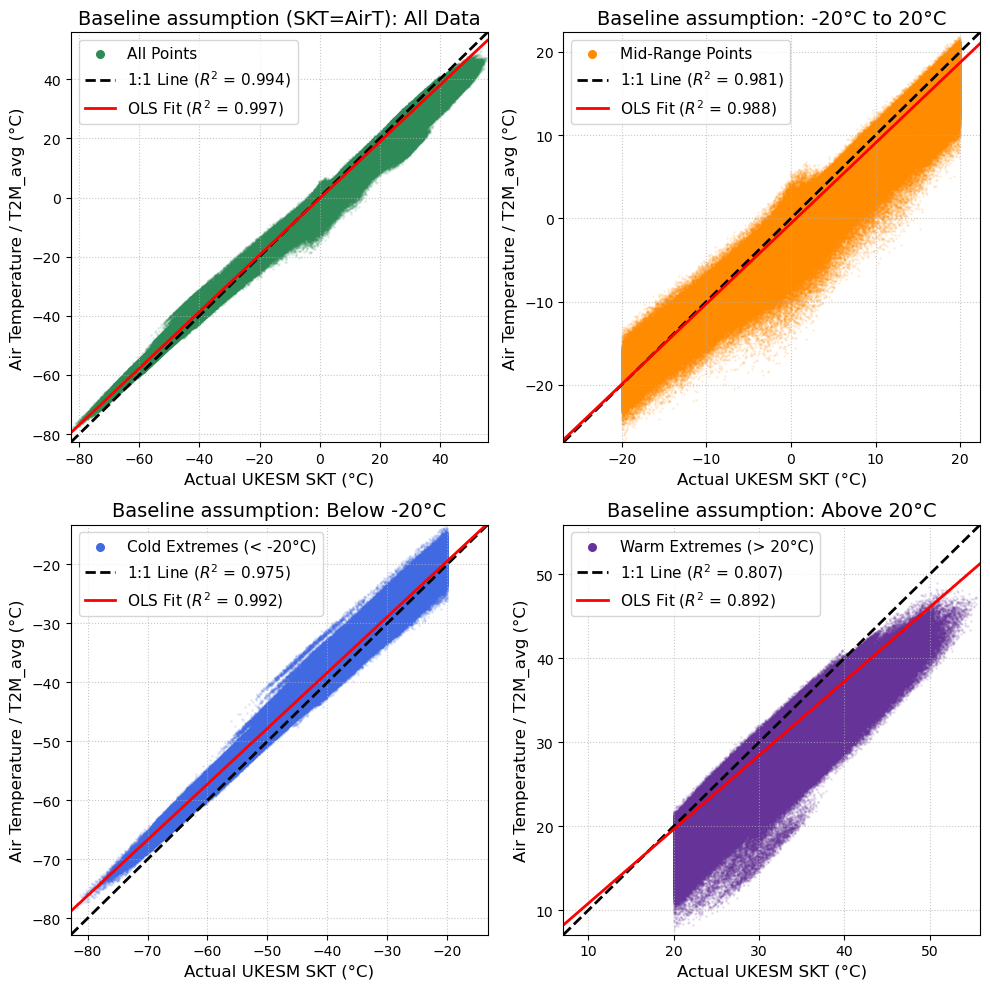

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
from scipy.stats import linregress

# --- THE FIX ---
# Extract the actual SKT and the Baseline (T2M_avg) from ds_cardamom, 
# flatten them into a dataframe, and drop any NaNs (like ocean pixels).
df_plot_base = ds_cardamom[['SKT', 'T2M_avg']].to_dataframe().dropna()

y_actual = df_plot_base['SKT'].values
y_baseline = df_plot_base['T2M_avg'].values
# ---------------

# Define the masks, colors, and titles for our 4 subplots
plot_configs = [
    {
        "mask": np.ones_like(y_actual, dtype=bool), # All True (No filter)
        "title": "Baseline assumption (SKT=AirT): All Data",
        "color": "seagreen",
        "label": "All Points"
    },
    {
        "mask": (y_actual >= -20) & (y_actual <= 20),
        "title": "Baseline assumption: -20°C to 20°C",
        "color": "darkorange",
        "label": "Mid-Range Points"
    },
    {
        "mask": y_actual < -20,
        "title": "Baseline assumption: Below -20°C",
        "color": "royalblue",
        "label": "Cold Extremes (< -20°C)"
    },
    {
        "mask": y_actual > 20,
        "title": "Baseline assumption: Above 20°C",
        "color": "rebeccapurple", 
        "label": "Warm Extremes (> 20°C)"
    }
]

# Set up a 2x2 figure grid
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs = axs.flatten()

# Loop through each configuration and plot
for ax, config in zip(axs, plot_configs):
    # Apply the mask to isolate the specific subset of data
    yt_sub = y_actual[config["mask"]]
    yp_sub = y_baseline[config["mask"]]
    
    # Recalculate metrics for ONLY this subset
    r2_1to1_sub = r2_score(yt_sub, yp_sub)
    slope, intercept, r_value, p_value, std_err = linregress(yt_sub, yp_sub)
    r2_ols_sub = r_value**2
    
    # Scatter plot
    ax.scatter(yt_sub, yp_sub, alpha=0.1, s=1, color=config["color"], label=config["label"])
    
    # Determine limits dynamically based on the subset to make it square
    min_val = min(yt_sub.min(), yp_sub.min())
    max_val = max(yt_sub.max(), yp_sub.max())
    limits = [min_val, max_val]
    
    # Plot the lines
    ax.plot(limits, limits, color='black', linestyle='--', linewidth=2, 
             label=f'1:1 Line ($R^2$ = {r2_1to1_sub:.3f})')
    
    ols_line = slope * np.array(limits) + intercept
    ax.plot(limits, ols_line, color='red', linestyle='-', linewidth=2, 
             label=f'OLS Fit ($R^2$ = {r2_ols_sub:.3f})')
    
    # Formatting
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_xlabel('Actual UKESM SKT (°C)', fontsize=12)
    ax.set_ylabel('Air Temperature / T2M_avg (°C)', fontsize=12)
    ax.set_title(config["title"], fontsize=14)
    
    # Fixed Legend
    legend = ax.legend(loc='upper left', fontsize=11)
    for handle in legend.legend_handles:
        if hasattr(handle, 'set_alpha'):
            handle.set_alpha(1.0)
        if hasattr(handle, 'set_sizes'):
            handle.set_sizes([30.0])
        elif hasattr(handle, 'set_linewidth'):
            handle.set_linewidth(2.0)
            
    ax.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

# Produce WIE-MIP driver

In [9]:
WIEMIP=xr.load_dataset('/Users/bilir/Desktop/CardamomScratch/WIE-MIP_drivers/Stable_Climate/stable_climate_monthly.nc')
WIEMIP['T2M_avg']=0.5*(WIEMIP['T2M_MAX']+WIEMIP['T2M_MIN'])
WIEMIP['T2M_DTR']=WIEMIP['T2M_MAX']-WIEMIP['T2M_MIN']

In [10]:
import xarray as xr
import pandas as pd
import numpy as np

# Load data and calculate derived features
# WIEMIP = xr.load_dataset('/Users/bilir/Desktop/CardamomScratch/WIE-MIP_drivers/1pctCO2/UKESM1-0-LL_1pctCO2_monthly.nc')
# WIEMIP['T2M_avg'] = 0.5 * (WIEMIP['T2M_MAX'] + WIEMIP['T2M_MIN'])
# WIEMIP['T2M_DTR'] = WIEMIP['T2M_MAX'] - WIEMIP['T2M_MIN']

print("Starting chunked GAM prediction to save memory...\n")

features = ['T2M_avg', 'T2M_DTR', 'VPD', 'TOTAL_PREC', 'SSRD', 'STRD', 'WIND']

time_steps = len(WIEMIP.time)
chunk_size = 600 

predicted_chunks = []

for start_idx in range(0, time_steps, chunk_size):
    end_idx = min(start_idx + chunk_size, time_steps)
    print(f"Processing time steps {start_idx} to {end_idx - 1}...")
    
    # 1. Slice the xarray dataset to just this 50-year chunk
    ds_chunk = WIEMIP.isel(time=slice(start_idx, end_idx))
    
    # 2. Convert to DataFrame BUT DO NOT DROP NAs YET
    # This preserves the perfect time, lat, lon scaffold
    df_chunk = ds_chunk[features].to_dataframe()
    
    # Strip out any duplicated index rows caused by overlapping chunk boundaries
    df_chunk = df_chunk[~df_chunk.index.duplicated(keep='first')]
    
    # --- THE FIX ---
    # 3. Create a boolean mask of rows that have no missing features
    valid_mask = df_chunk.notna().all(axis=1)
    
    # 4. Extract ONLY the valid rows to feed into the GAM
    X_chunk = df_chunk.loc[valid_mask, features].values
    
    # 5. Initialize the prediction column with NaNs
    df_chunk['SKT_PREDICTED_GAM'] = np.nan
    
    # 6. Slot the GAM predictions back into the dataframe ONLY where data is valid
    if len(X_chunk) > 0:
        df_chunk.loc[valid_mask, 'SKT_PREDICTED_GAM'] = gam.predict(X_chunk)
    # ---------------
    
    # 7. Convert ONLY the prediction column back to an xarray Dataset
    # Because we didn't drop rows, the coordinates will perfectly match WIEMIP
    ds_pred_chunk = df_chunk[['SKT_PREDICTED_GAM']].to_xarray()
    
    predicted_chunks.append(ds_pred_chunk)
    
    del ds_chunk, df_chunk, X_chunk, valid_mask

print("\nAll chunks processed! Concatenating back into a single spatial dataset...")

# Stitch the chunks back together along the time axis
WIEMIP_skt = xr.concat(predicted_chunks, dim='time')

# Add metadata
WIEMIP_skt['SKT_PREDICTED_GAM'].attrs.update({
    'source': 'Generalized Additive Model (GAM) trained on ERA5',
    'units': 'degrees Celsius'
})

# # Merge the predicted SKT back into the master WIEMIP dataset
# WIEMIP = xr.merge([WIEMIP, WIEMIP_skt])

# print("Done! Your master 'WIEMIP' dataset is fully prepped.")
# print(WIEMIP['SKT_PREDICTED_GAM'])

Starting chunked GAM prediction to save memory...

Processing time steps 0 to 259...

All chunks processed! Concatenating back into a single spatial dataset...


In [11]:
WIEMIP_skt['SKT_PREDICTED_GAM']

<xarray.DataArray 'SKT_PREDICTED_GAM' (time: 241, lat: 180, lon: 360)> Size: 125MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(241, 180, 360))
Coordinates:
  * time     (time) object 2kB 1850-01-31 00:00:00 ... 1870-01-31 00:00:00
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes:
    source:   Generalized Additive Model (GAM) trained on ERA5
    units:    degrees Celsius

In [12]:
WIEMIP

<xarray.Dataset> Size: 674MB
Dimensions:     (time: 260, lat: 180, lon: 360)
Coordinates:
  * lon         (lon) float64 3kB -179.5 -178.5 -177.5 ... 177.5 178.5 179.5
  * lat         (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
  * time        (time) object 2kB 1850-01-31 00:00:00 ... 1870-01-31 00:00:00
Data variables:
    T2M_MAX     (time, lat, lon) float32 67MB nan nan nan nan ... nan nan nan
    T2M_MIN     (time, lat, lon) float32 67MB nan nan nan nan ... nan nan nan
    VPD         (time, lat, lon) float32 67MB nan nan nan nan ... nan nan nan
    TOTAL_PREC  (time, lat, lon) float32 67MB nan nan nan nan ... nan nan nan
    SNOWFALL    (time, lat, lon) float32 67MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    SSRD        (time, lat, lon) float32 67MB nan nan nan nan ... nan nan nan
    STRD        (time, lat, lon) float32 67MB nan nan nan nan ... nan nan nan
    WIND        (time, lat, lon) float32 67MB nan nan nan nan ... nan nan nan
    T2M_avg     (time, lat, lon) float32 67MB nan nan nan nan ... nan nan nan
    T2M_DTR     (time, lat, lon) float32 67MB nan nan nan nan ... nan nan nan
Attributes:
    source:                     Stable climate dataset (30 years), 1deg, conv...
    processing_notes:           Aggregated to monthly scale. Specific process...
    T2M_MAX_derivation:         Monthly mean of daily maximum temperature. Le...
    T2M_MIN_derivation:         Monthly mean of daily minimum temperature. Le...
    VPD_derivation:             Monthly mean of daily maximum VPD. Leverages ...
    TOTAL_PREC_derivation:      Monthly mean precipitation rate. Leverages 6h...
    SNOWFALL_derivation:        Monthly mean snowfall rate. Leverages 6hr pre...
    SSRD_STRD_WIND_derivation:  Standard monthly mean. Leverages 6hr dswrf, d...

In [13]:
import xarray as xr

print(f"Original WIEMIP time steps: {len(WIEMIP.time)}")

# 1. Extract the time coordinate as a Pandas Index
time_index = WIEMIP.time.to_index()

# 2. Create a mask that drops duplicates, matching the logic we used in the GAM loop
dedup_mask = ~time_index.duplicated(keep='first')

# 3. Slice the master dataset to drop the 150 ghost Januaries
WIEMIP = WIEMIP.isel(time=dedup_mask)
print(f"Cleaned WIEMIP time steps: {len(WIEMIP.time)}")

# 4. Now the merge will work perfectly!
WIEMIP = xr.merge([WIEMIP, WIEMIP_skt])

print("\n✅ Success! The datasets are merged.")
print(WIEMIP['SKT_PREDICTED_GAM'])

Original WIEMIP time steps: 260
Cleaned WIEMIP time steps: 241

✅ Success! The datasets are merged.
<xarray.DataArray 'SKT_PREDICTED_GAM' (time: 241, lat: 180, lon: 360)> Size: 125MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan

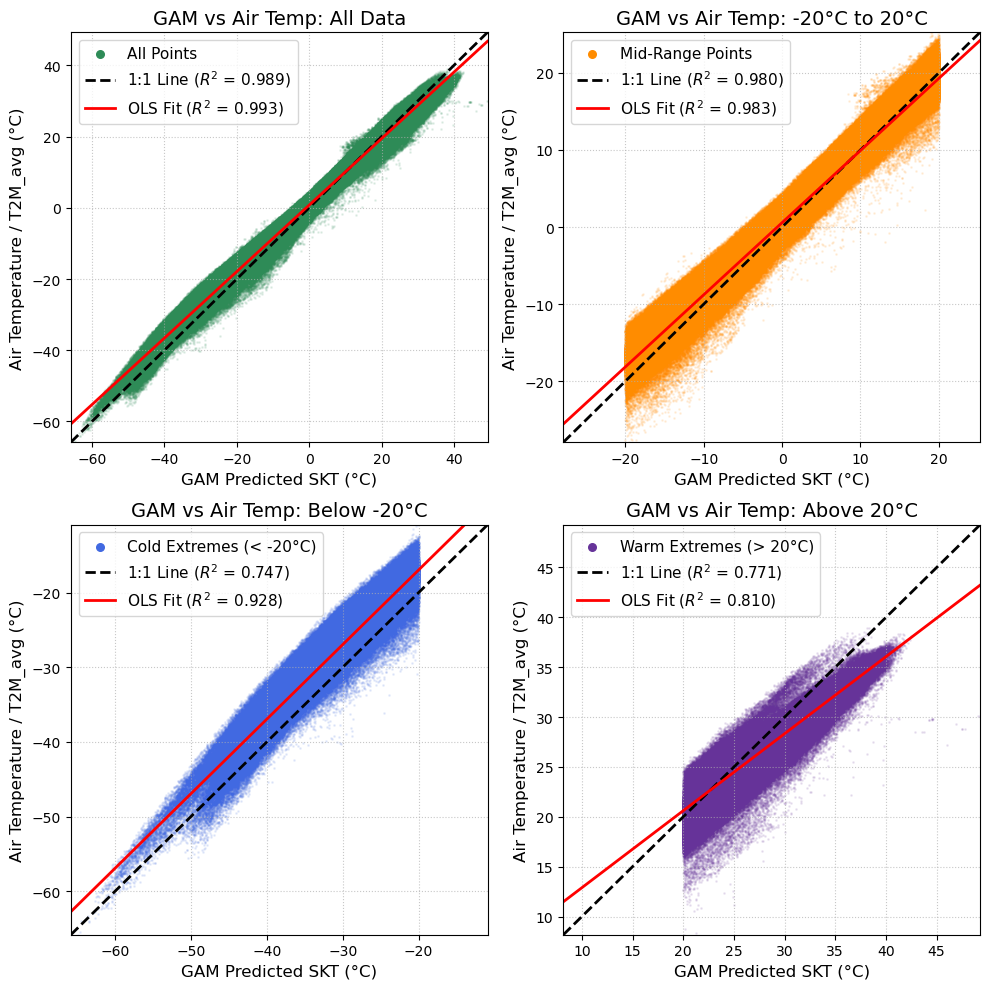

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score
from scipy.stats import linregress

# --- THE FIX ---
# Extract the Air Temp (T2M_avg) and GAM Predicted SKT from WIEMIP, 
# flatten them into a dataframe, and drop any NaNs (like ocean pixels).
df_plot_base = WIEMIP[['T2M_avg', 'SKT_PREDICTED_GAM']].to_dataframe().dropna()

# Set the GAM prediction as "x" and T2M_avg as "y"
x_vals = df_plot_base['SKT_PREDICTED_GAM'].values
y_vals = df_plot_base['T2M_avg'].values
# ---------------

# Define the masks, colors, and titles for our 4 subplots
plot_configs = [
    {
        "mask": np.ones_like(x_vals, dtype=bool), # All True (No filter)
        "title": "GAM vs Air Temp: All Data",
        "color": "seagreen",
        "label": "All Points"
    },
    {
        "mask": (x_vals >= -20) & (x_vals <= 20),
        "title": "GAM vs Air Temp: -20°C to 20°C",
        "color": "darkorange",
        "label": "Mid-Range Points"
    },
    {
        "mask": x_vals < -20,
        "title": "GAM vs Air Temp: Below -20°C",
        "color": "royalblue",
        "label": "Cold Extremes (< -20°C)"
    },
    {
        "mask": x_vals > 20,
        "title": "GAM vs Air Temp: Above 20°C",
        "color": "rebeccapurple", 
        "label": "Warm Extremes (> 20°C)"
    }
]

# Set up a 2x2 figure grid
fig, axs = plt.subplots(2, 2, figsize=(10, 10))
axs = axs.flatten()

# Loop through each configuration and plot
for ax, config in zip(axs, plot_configs):
    # Apply the mask to isolate the specific subset of data
    x_sub = x_vals[config["mask"]]
    y_sub = y_vals[config["mask"]]
    
    # Recalculate metrics for ONLY this subset
    r2_1to1_sub = r2_score(x_sub, y_sub)
    slope, intercept, r_value, p_value, std_err = linregress(x_sub, y_sub)
    r2_ols_sub = r_value**2
    
    # Scatter plot
    ax.scatter(x_sub, y_sub, alpha=0.1, s=1, color=config["color"], label=config["label"])
    
    # Determine limits dynamically based on the subset to make it square
    min_val = min(x_sub.min(), y_sub.min())
    max_val = max(x_sub.max(), y_sub.max())
    limits = [min_val, max_val]
    
    # Plot the lines
    ax.plot(limits, limits, color='black', linestyle='--', linewidth=2, 
             label=f'1:1 Line ($R^2$ = {r2_1to1_sub:.3f})')
    
    ols_line = slope * np.array(limits) + intercept
    ax.plot(limits, ols_line, color='red', linestyle='-', linewidth=2, 
             label=f'OLS Fit ($R^2$ = {r2_ols_sub:.3f})')
    
    # Formatting
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_xlabel('GAM Predicted SKT (°C)', fontsize=12)
    ax.set_ylabel('Air Temperature / T2M_avg (°C)', fontsize=12)
    ax.set_title(config["title"], fontsize=14)
    
    # Fixed Legend
    legend = ax.legend(loc='upper left', fontsize=11)
    for handle in legend.legend_handles:
        if hasattr(handle, 'set_alpha'):
            handle.set_alpha(1.0)
        if hasattr(handle, 'set_sizes'):
            handle.set_sizes([30.0])
        elif hasattr(handle, 'set_linewidth'):
            handle.set_linewidth(2.0)
            
    ax.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.show()

In [15]:
WIEMIP.to_netcdf('/Users/bilir/Desktop/CardamomScratch/WIE-MIP_drivers/Stable_Climate/UKESM1-0-LL_Stable_monthly_withGAM_SKT.nc')